# Tornado Data Analysis in Kansas, Oklahoma, & Texas 1/1/2020-7/31/2024
Morgan Noonan
men83@pitt.edu

## Project Abstract
Can machine learning help predict the Enhanced Fujita (EF) scale of a tornado?

I am interested in this question because the United States experiences a lot of devasting tornados killing a lot of people each year. What I'm looking to do is help predict the tornado's strength to better predict the damage to follow. Considering the dates, size, time, and dimensions of the tornado along with their damage costs can help prepare rescue teams for catastrophic tornados. 

This will be helpful to people in areas where tornados are very common. Meteorologists can use this to predict the possible devastation and warn those in the area with better preparation.

The datasets I use in this analysis are for Kansas, Oklahoma, and Texas and they are from the National Centers for Environmental Information, National Oceanic and Atmospheric Administration [(NOAA)](https://www.ncdc.noaa.gov/stormev)


### The Problem we are trying to solve


In [385]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from itertools import combinations
import matplotlib.dates as mdates

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

### Open data file

In [387]:
# Open the first data file
d4 = pd.read_csv('kansas_results.csv')
d3 = pd.read_csv('oklahoma_results.csv')
d2 = pd.read_csv('texas_results.csv')
d1 = pd.concat([d4, d3, d2], ignore_index=True)

pd.set_option('display.max_columns', None)
d1.head()

,EVENT_ID,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,BEGIN_TIME,EVENT_TYPE,MAGNITUDE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,CZ_TIMEZONE,MAGNITUDE_TYPE,EPISODE_ID,CZ_TYPE,CZ_FIPS,WFO,INJURIES_INDIRECT,DEATHS_INDIRECT,SOURCE,FLOOD_CAUSE,TOR_LENGTH,TOR_WIDTH,BEGIN_RANGE,BEGIN_AZIMUTH,END_RANGE,END_AZIMUTH,END_LOCATION,END_DATE,END_TIME,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EVENT_NARRATIVE,EPISODE_NARRATIVE,ABSOLUTE_ROWNUMBER
0,881789,LYON CO.,BUSHONG,05/14/2020,1905,Tornado,,EFU,0,0,0,0,KS,CST-6,,146694,C,111,TOP,0,0,Storm Chaser,,2.66,25,5,NW,7,NNW,BUSHONG,05/14/2020,1909,38.7100,-96.3100,38.7400,-96.3000,Storm chasers reported a small tornado on the ...,A cluster of severe t-storms some supercells d...,1
1,881791,WABAUNSEE CO.,ALTA VISTA,05/14/2020,1920,Tornado,,EFU,0,0,0,0,KS,CST-6,,146694,C,197,TOP,0,0,Storm Chaser,,0.97,75,3,ENE,4,ENE,ALTA VISTA,05/14/2020,1926,38.8900,-96.4214,38.8860,-96.4041,Storm chasers also reported a small tornado on...,A cluster of severe t-storms some supercells d...,2
2,881788,MORRIS CO.,HOUCKE,05/14/2020,1949,Tornado,,EFU,0,0,0,0,KS,CST-6,,146694,C,127,TOP,0,0,Storm Chaser,,3.69,50,5,SW,2,S,COUNCIL GROVE,05/14/2020,2000,38.5674,-96.4891,38.6207,-96.4852,Storm chasers reported a small tornado on the ...,A cluster of severe t-storms some supercells d...,3
3,881793,LYON CO.,BUSHONG,05/14/2020,1953,Tornado,,EF0,0,0,0,0,KS,CST-6,,146694,C,111,TOP,0,0,Storm Chaser,,1.60,50,3,NW,3,NNW,BUSHONG,05/14/2020,2006,38.6790,-96.2829,38.6971,-96.2644,Additional supercell t-storms developed after ...,A cluster of severe t-storms some supercells d...,4
4,894116,GREELEY CO.,WHITELAW,05/21/2020,1233,Tornado,,EFU,0,0,0,0,KS,MST-7,,148214,C,71,GLD,0,0,Storm Chaser,,0.01,50,15,NNE,15,NNE,WHITELAW,05/21/2020,1233,38.6600,-101.6000,38.6600,-101.6000,Weak landspout tornado reported. Difficult to ...,During the early afternoon a landspout was rep...,5


The dataset is organized to look at location data and time first. Then it transitions to its EF scale, the amount of disaster by land and human injuries. It then goes to location again by state, timezone and zone followe by its source, and tornado characeristics such as the length, width, latitude and longitude. 

### Getting rid of unneeded 


In [390]:
d1.drop(columns=['EVENT_ID'], inplace=True)
d1.drop(columns=['MAGNITUDE'], inplace=True)
d1.drop(columns=['MAGNITUDE_TYPE'], inplace=True)
d1.drop(columns=['FLOOD_CAUSE'], inplace=True)
d1.drop(columns=['EPISODE_ID'], inplace=True)
d1.drop(columns=['EVENT_NARRATIVE'], inplace=True)
d1.drop(columns=['EPISODE_NARRATIVE'], inplace=True)
d1.drop(columns=['ABSOLUTE_ROWNUMBER'], inplace=True)
d1.drop(columns=['EVENT_TYPE'], inplace=True)
d1.drop(columns=['CZ_TYPE'], inplace=True)
d1.drop(columns=['CZ_FIPS'], inplace=True)
d1.drop(columns=['CZ_TIMEZONE'], inplace=True)
d1.drop(columns=['WFO'], inplace=True)
d1.drop(columns=['BEGIN_RANGE'], inplace=True)
d1.drop(columns=['END_RANGE'], inplace=True)
d1.drop(columns=['END_LON'], inplace=True)
d1.drop(columns=['END_LAT'], inplace=True)
d1.drop(columns=['BEGIN_LON'], inplace=True)
d1.drop(columns=['BEGIN_LAT'], inplace=True)
d1.drop(columns=['END_AZIMUTH'], inplace=True)
d1.drop(columns=['BEGIN_AZIMUTH'], inplace=True)
d1.drop(columns=['SOURCE'], inplace=True)

These columns were dropped because they are not helpful in making a linear regression model and are very specific characters to location. SOme columns were completely blank and others involved weather characteristics not relevant to tornados. 

### Checking for missing values

In [393]:
d1.isnull().sum()

CZ_NAME_STR            0
BEGIN_LOCATION         0
BEGIN_DATE             0
BEGIN_TIME             0
TOR_F_SCALE            0
DEATHS_DIRECT          0
INJURIES_DIRECT        0
DAMAGE_PROPERTY_NUM    0
DAMAGE_CROPS_NUM       0
STATE_ABBR             0
INJURIES_INDIRECT      0
DEATHS_INDIRECT        0
TOR_LENGTH             0
TOR_WIDTH              0
END_LOCATION           0
END_DATE               0
END_TIME               0
dtype: int64

### Removing EFU's and Changing Data Types
(tornadoes that have been sighted but did not touch ground or destroy anything noticable, too weak) these do not reach EF0

In [395]:
d1 = d1[~d1['TOR_F_SCALE'].isin(['EFU'])]
d1.tail(50)

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,BEGIN_TIME,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,INJURIES_INDIRECT,DEATHS_INDIRECT,TOR_LENGTH,TOR_WIDTH,END_LOCATION,END_DATE,END_TIME
1006,SMITH CO.,TEASELVILLE,05/23/2024,1809,EF1,0,0,0,0,TX,0,0,1.60,480,TEASELVILLE,05/23/2024,1810
1007,LIMESTONE CO.,HARMONY,05/23/2024,1815,EF0,0,0,0,0,TX,0,0,3.41,300,HARMONY,05/23/2024,1828
1008,ROBERTSON CO.,BOLD PRAIRIE,05/23/2024,1828,EF0,0,0,0,0,TX,0,0,11.50,300,BOLD PRAIRIE,05/23/2024,1850
1009,BOWIE CO.,DANIELS CHAPEL,05/24/2024,1805,EF1,0,0,0,0,TX,0,0,1.83,275,DANIELS CHAPEL,05/24/2024,1809
1010,ARCHER CO.,WINDTHORST,05/25/2024,1616,EF1,0,0,0,0,TX,0,0,1.13,200,WINDTHORST,05/25/2024,1619
1011,CLAY CO.,JOY,05/25/2024,1619,EF1,0,0,20000,0,TX,0,0,2.30,200,JOY,05/25/2024,1624
1012,CLAY CO.,BLUEGROVE,05/25/2024,1633,EF1,0,0,2000,0,TX,0,0,3.40,100,BLUEGROVE,05/25/2024,1641
1013,EASTLAND CO.,PIONEER,05/25/2024,1642,EF2,0,0,100000,0,TX,0,0,2.46,70,PIONEER,05/25/2024,1648
1014,MONTAGUE CO.,SATONA,05/25/2024,2039,EF2,0,0,0,0,TX,0,0,15.40,1100,FORESTBURG,05/25/2024,2108
1015,COOKE CO.,PRAIRIE PT,05/25/2024,2108,EF3,7,80,15000000,0,TX,0,0,25.41,1200,MOUNTAIN SPGS,05/25/2024,2149


In [396]:
d1['TOR_F_SCALE'] = d1['TOR_F_SCALE'].str.replace('EF', '').astype(int)

#### change BEGIN_TIME and END_TIME to be in military time obejct format

In [398]:
d1['BEGIN_TIME'] = d1['BEGIN_TIME'].apply(lambda x: f"{x:04d}")  # Pad with zeros to ensure four digits
d1['BEGIN_TIME'] = d1['BEGIN_TIME'].str.slice(0, 2) + ':' + d1['BEGIN_TIME'].str.slice(2)
d1['END_TIME'] = d1['END_TIME'].apply(lambda x: f"{x:04d}")  # Pad with zeros to ensure four digits
d1['END_TIME'] = d1['END_TIME'].str.slice(0, 2) + ':' + d1['END_TIME'].str.slice(2)
d1.dtypes

CZ_NAME_STR             object
BEGIN_LOCATION          object
BEGIN_DATE              object
BEGIN_TIME              object
TOR_F_SCALE              int64
DEATHS_DIRECT            int64
INJURIES_DIRECT          int64
DAMAGE_PROPERTY_NUM      int64
DAMAGE_CROPS_NUM         int64
STATE_ABBR              object
INJURIES_INDIRECT        int64
DEATHS_INDIRECT          int64
TOR_LENGTH             float64
TOR_WIDTH                int64
END_LOCATION            object
END_DATE                object
END_TIME                object
dtype: object

columns I will be finding how long each tornado lasted from the BEGIN_TIME and END_TIME columns.

In [400]:
d1['BEGIN_DATETIME'] = pd.to_datetime(d1['BEGIN_DATE'] + ' ' + d1['BEGIN_TIME'], errors='coerce')
d1['END_DATETIME'] = pd.to_datetime(d1['END_DATE'] + ' ' + d1['END_TIME'], errors='coerce')
d1['DURATION'] = d1['END_DATETIME'] - d1['BEGIN_DATETIME']
d1['DURATION'] = d1['DURATION'].dt.total_seconds()

In [401]:
d1.drop(columns=['BEGIN_TIME'], inplace=True)
d1.drop(columns=['END_DATE'], inplace=True)
d1.drop(columns=['END_TIME'], inplace=True)

In [402]:
d1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 789 entries, 3 to 1064
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   CZ_NAME_STR          789 non-null    object        
 1   BEGIN_LOCATION       789 non-null    object        
 2   BEGIN_DATE           789 non-null    object        
 3   TOR_F_SCALE          789 non-null    int64         
 4   DEATHS_DIRECT        789 non-null    int64         
 5   INJURIES_DIRECT      789 non-null    int64         
 6   DAMAGE_PROPERTY_NUM  789 non-null    int64         
 7   DAMAGE_CROPS_NUM     789 non-null    int64         
 8   STATE_ABBR           789 non-null    object        
 9   INJURIES_INDIRECT    789 non-null    int64         
 10  DEATHS_INDIRECT      789 non-null    int64         
 11  TOR_LENGTH           789 non-null    float64       
 12  TOR_WIDTH            789 non-null    int64         
 13  END_LOCATION         789 non-null    ob

In [403]:
d1.head()

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,INJURIES_INDIRECT,DEATHS_INDIRECT,TOR_LENGTH,TOR_WIDTH,END_LOCATION,BEGIN_DATETIME,END_DATETIME,DURATION
3,LYON CO.,BUSHONG,05/14/2020,0,0,0,0,0,KS,0,0,1.60,50,BUSHONG,2020-05-14 19:53:00,2020-05-14 20:06:00,780.0
5,HAMILTON CO.,COOLIDGE,05/21/2020,0,0,0,0,0,KS,0,0,0.56,50,COOLIDGE,2020-05-21 14:15:00,2020-05-21 14:17:00,120.0
6,HAMILTON CO.,COOLIDGE,05/21/2020,0,0,0,0,0,KS,0,0,0.31,50,COOLIDGE,2020-05-21 14:15:00,2020-05-21 14:18:00,180.0
7,STANTON CO.,JOHNSON,05/21/2020,0,0,0,0,0,KS,0,0,0.07,30,JOHNSON,2020-05-21 14:41:00,2020-05-21 14:42:00,60.0
8,HAMILTON CO.,SYRACUSE,05/21/2020,0,0,0,0,0,KS,0,0,0.07,50,SYRACUSE,2020-05-21 16:06:00,2020-05-21 16:07:00,60.0


This allows me to see what column data types are most useful and if any others need to be changed so I can use the min my analysis. 

### Provide written justification explaining why you selected particular methods for dealing with missing values
The dataset does not have any missing values, so there is nothing that needs to be done as far as imputation
### Check for outliers. Do we keep them or do we drop them?  Why? 

#### DEATHS_DIRECT

<Axes: >

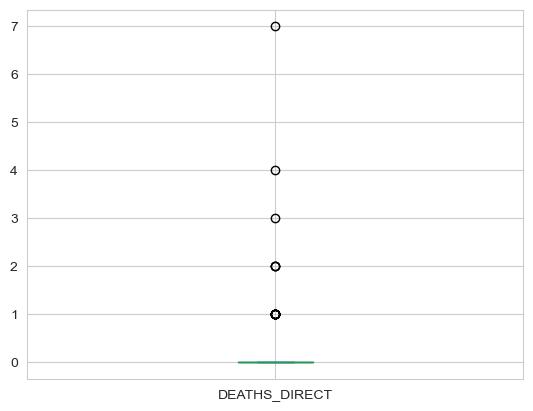

In [407]:
d1['DEATHS_DIRECT'].plot.box()

In [408]:
d1.sort_values('DEATHS_DIRECT', ascending=False).head(17)

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,INJURIES_INDIRECT,DEATHS_INDIRECT,TOR_LENGTH,TOR_WIDTH,END_LOCATION,BEGIN_DATETIME,END_DATETIME,DURATION
1015,COOKE CO.,PRAIRIE PT,05/25/2024,3,7,80,15000000,0,TX,0,0,25.41,1200,MOUNTAIN SPGS,2024-05-25 21:08:00,2024-05-25 21:49:00,2460.0
915,MOTLEY CO.,WHITEFLAT,06/21/2023,3,4,15,0,0,TX,0,0,9.14,600,MATADOR,2023-06-21 18:51:00,2023-06-21 19:09:00,1080.0
906,OCHILTREE CO.,PERRYTON,06/15/2023,3,3,100,1000000,0,TX,0,0,6.31,880,PERRYTON MUNI ARPT,2023-06-15 16:06:00,2023-06-15 16:17:00,660.0
506,HUGHES CO.,SPAULDING,04/27/2024,3,2,4,1500000,0,OK,0,0,20.50,1760,WETUMKA,2024-04-27 21:36:00,2024-04-27 22:04:00,1680.0
539,OSAGE CO.,OSAGE,05/06/2024,4,2,33,10000000,0,OK,0,0,32.40,1700,OKESA,2024-05-06 20:12:00,2024-05-06 20:57:00,2700.0
582,MAYES CO.,PRYOR,05/25/2024,3,2,4,5000000,0,OK,0,0,5.20,1400,PRYOR,2024-05-25 22:48:00,2024-05-25 22:59:00,660.0
379,ROGER MILLS CO.,CHEYENNE,02/26/2023,2,1,3,250000,0,OK,0,0,7.00,500,STRONG CITY,2023-02-26 19:13:00,2023-02-26 19:18:00,300.0
886,CAMERON CO.,BAYSIDE,05/13/2023,1,1,11,500000,0,TX,0,0,0.45,200,BAYSIDE,2023-05-13 03:06:00,2023-05-13 03:08:00,120.0
400,MCCLAIN CO.,DIBBLE,04/19/2023,3,1,2,4000000,0,OK,0,0,10.90,1200,GOLDSBY,2023-04-19 18:30:00,2023-04-19 19:05:00,2100.0
637,PANOLA CO.,CARTHAGE,03/27/2021,2,1,3,1500000,0,TX,0,0,15.84,1600,FRONT,2021-03-27 18:38:00,2021-03-27 19:05:00,1620.0


Based on the F scale, the location, and property damage it makes sense that this is high. It would not consider it an outlier.

#### INJURIES_DIRECT

<Axes: >

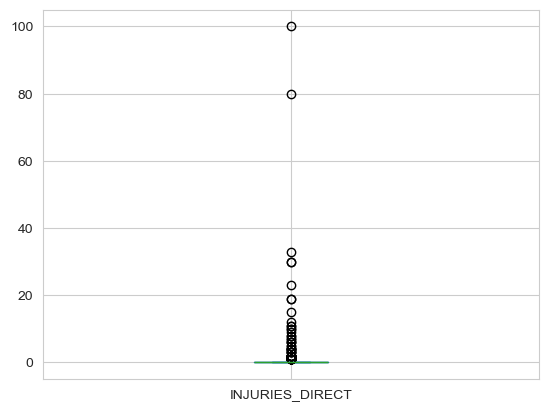

In [411]:
d1['INJURIES_DIRECT'].plot.box()

In [412]:
d1.sort_values('INJURIES_DIRECT', ascending=False).head(20)

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,INJURIES_INDIRECT,DEATHS_INDIRECT,TOR_LENGTH,TOR_WIDTH,END_LOCATION,BEGIN_DATETIME,END_DATETIME,DURATION
906,OCHILTREE CO.,PERRYTON,06/15/2023,3,3,100,1000000,0,TX,0,0,6.31,880,PERRYTON MUNI ARPT,2023-06-15 16:06:00,2023-06-15 16:17:00,660.0
1015,COOKE CO.,PRAIRIE PT,05/25/2024,3,7,80,15000000,0,TX,0,0,25.41,1200,MOUNTAIN SPGS,2024-05-25 21:08:00,2024-05-25 21:49:00,2460.0
539,OSAGE CO.,OSAGE,05/06/2024,4,2,33,10000000,0,OK,0,0,32.40,1700,OKESA,2024-05-06 20:12:00,2024-05-06 20:57:00,2700.0
997,BELL CO.,(TPL)TEMPLE MUNI ARP,05/22/2024,2,0,30,5000000,0,TX,0,0,2.78,420,MIDWAY,2024-05-22 17:21:00,2024-05-22 17:26:00,300.0
504,MURRAY CO.,SULPHUR,04/27/2024,3,1,30,10000000,0,OK,0,0,9.63,440,HICKORY,2024-04-27 21:23:00,2024-04-27 21:36:00,780.0
775,BELL CO.,YOUNGSPORT,04/12/2022,3,0,23,0,0,TX,0,0,13.01,770,UNION GROVE,2022-04-12 16:34:00,2022-04-12 17:06:00,1920.0
581,ROGERS CO.,COLLINSVILLE,05/25/2024,3,0,19,40000000,0,OK,0,0,18.70,2000,SEQUOYAH,2024-05-25 22:19:00,2024-05-25 22:48:00,1740.0
500,CARTER CO.,ARDMORE,04/27/2024,2,0,19,20000000,0,OK,0,0,11.30,400,SPRINGER,2024-04-27 20:42:00,2024-04-27 20:56:00,840.0
915,MOTLEY CO.,WHITEFLAT,06/21/2023,3,4,15,0,0,TX,0,0,9.14,600,MATADOR,2023-06-21 18:51:00,2023-06-21 19:09:00,1080.0
389,CLEVELAND CO.,NORMAN,02/26/2023,2,0,12,50000000,0,OK,0,0,20.00,900,STELLA,2023-02-26 21:19:00,2023-02-26 21:38:00,1140.0


Based on location, F scale, and number of deaths and preoprty damange it is reasonable to assume that these outliers properly represent those tornadoes. I would not consider them outliers.

#### DAMAGE_PROPERTY_NUM

<Axes: >

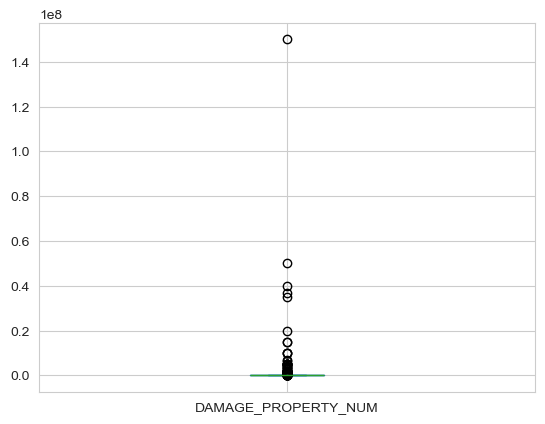

In [415]:
d1['DAMAGE_PROPERTY_NUM'].plot.box()

In [416]:
d1.sort_values('DAMAGE_PROPERTY_NUM', ascending=False).head(20)

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,INJURIES_INDIRECT,DEATHS_INDIRECT,TOR_LENGTH,TOR_WIDTH,END_LOCATION,BEGIN_DATETIME,END_DATETIME,DURATION
511,LOVE CO.,MARIETTA,04/27/2024,4,1,6,150000000,0,OK,0,0,12.50,900,LAKE MURRAY DAM,2024-04-27 22:08:00,2024-04-27 22:23:00,900.0
389,CLEVELAND CO.,NORMAN,02/26/2023,2,0,12,50000000,0,OK,0,0,20.00,900,STELLA,2023-02-26 21:19:00,2023-02-26 21:38:00,1140.0
581,ROGERS CO.,COLLINSVILLE,05/25/2024,3,0,19,40000000,0,OK,0,0,18.70,2000,SEQUOYAH,2024-05-25 22:19:00,2024-05-25 22:48:00,1740.0
77,BUTLER CO.,ANDOVER,04/29/2022,3,0,1,37000000,0,KS,3,0,9.78,250,BENTON,2022-04-29 19:13:00,2022-04-29 19:31:00,1080.0
362,MCCURTAIN CO.,BOSS,11/04/2022,4,0,6,35000000,0,OK,0,0,32.30,1056,EAGLETOWN,2022-11-04 17:44:00,2022-11-04 18:21:00,2220.0
500,CARTER CO.,ARDMORE,04/27/2024,2,0,19,20000000,0,OK,0,0,11.30,400,SPRINGER,2024-04-27 20:42:00,2024-04-27 20:56:00,840.0
540,WASHINGTON CO.,BARTLESVILLE,05/06/2024,2,0,0,15000000,0,OK,0,0,8.40,1700,DEWEY,2024-05-06 20:57:00,2024-05-06 21:07:00,600.0
1015,COOKE CO.,PRAIRIE PT,05/25/2024,3,7,80,15000000,0,TX,0,0,25.41,1200,MOUNTAIN SPGS,2024-05-25 21:08:00,2024-05-25 21:49:00,2460.0
539,OSAGE CO.,OSAGE,05/06/2024,4,2,33,10000000,0,OK,0,0,32.40,1700,OKESA,2024-05-06 20:12:00,2024-05-06 20:57:00,2700.0
102,RILEY CO.,MANHATTAN,06/11/2022,2,0,0,10000000,0,KS,0,0,0.32,50,MANHATTAN,2022-06-11 18:20:00,2022-06-11 18:22:00,120.0


Because these are much higher scaled tornads (3-4) I believe that these numbers make sense on that scenario. I don't believe they are outliers because of their number but rather scale of how many lower ef scaled tornadoes there are in comparison to higher ones.

#### DAMAGE_CROPS NUM

<Axes: >

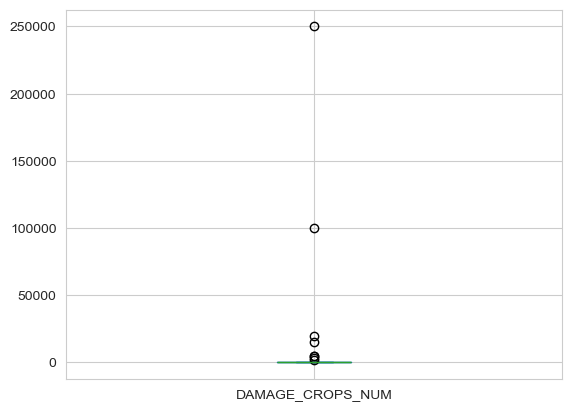

In [419]:
d1['DAMAGE_CROPS_NUM'].plot.box()

In [420]:
d1.sort_values('DAMAGE_CROPS_NUM', ascending=False).head(1)

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,INJURIES_INDIRECT,DEATHS_INDIRECT,TOR_LENGTH,TOR_WIDTH,END_LOCATION,BEGIN_DATETIME,END_DATETIME,DURATION
928,BEXAR CO.,SAN ANTONIO,10/26/2023,0,0,0,0,250000,TX,0,0,5.17,150,OLMOS PARK,2023-10-26 07:01:00,2023-10-26 07:18:00,1020.0


#### INJURIES_INDIRECT

<Axes: >

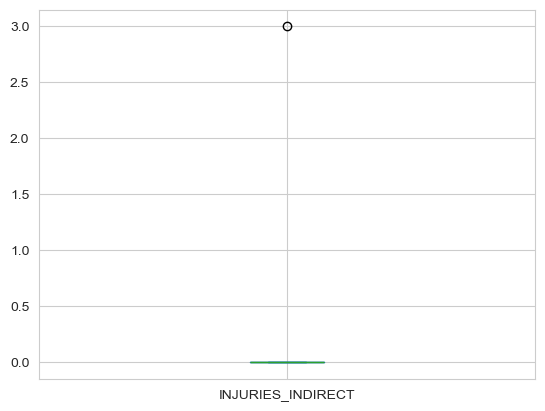

In [422]:
d1['INJURIES_INDIRECT'].plot.box()

Because there is nothing here other than zero, I will be dropping this column from the dataset

In [424]:
d1.drop(columns=['INJURIES_INDIRECT'], inplace=True)

#### DEATHS_INDIRECT

<Axes: >

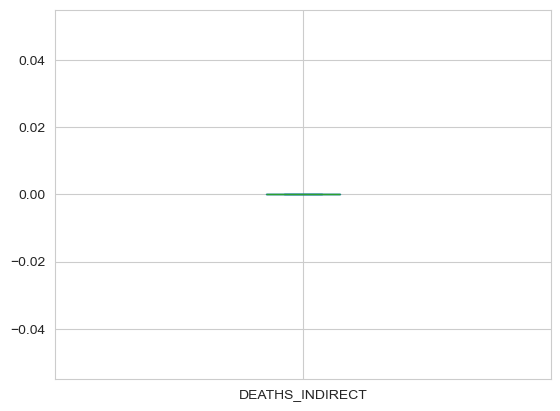

In [426]:
d1['DEATHS_INDIRECT'].plot.box()

Because there is nothing here other than zero, I will be dropping this column from the dataset

In [428]:
d1.drop(columns=['DEATHS_INDIRECT'], inplace=True)

#### TOR_LENGTH

<Axes: >

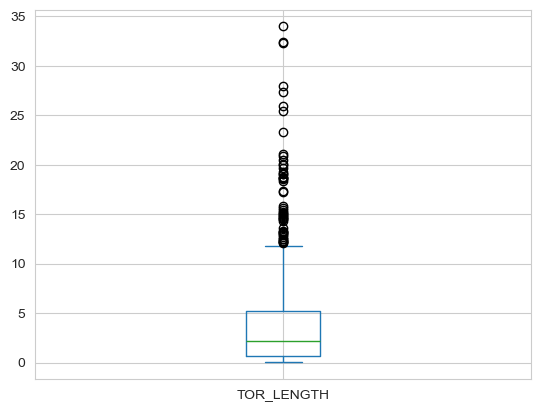

In [430]:
d1['TOR_LENGTH'].plot.box()

In [431]:
d1.sort_values('TOR_LENGTH', ascending=False).head(10)

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,TOR_LENGTH,TOR_WIDTH,END_LOCATION,BEGIN_DATETIME,END_DATETIME,DURATION
717,JACK CO.,BARTONS CHAPEL,03/21/2022,3,0,9,0,0,TX,33.97,880,TRUCE,2022-03-21 14:35:00,2022-03-21 15:18:00,2580.0
539,OSAGE CO.,OSAGE,05/06/2024,4,2,33,10000000,0,OK,32.40,1700,OKESA,2024-05-06 20:12:00,2024-05-06 20:57:00,2700.0
362,MCCURTAIN CO.,BOSS,11/04/2022,4,0,6,35000000,0,OK,32.30,1056,EAGLETOWN,2022-11-04 17:44:00,2022-11-04 18:21:00,2220.0
823,RED RIVER CO.,RUGBY,11/04/2022,4,0,7,2000000,0,TX,27.93,1056,ACWORTH,2022-11-04 17:15:00,2022-11-04 17:44:00,1740.0
729,WILLIAMSON CO.,ROUND ROCK,03/21/2022,2,0,0,0,0,TX,27.39,600,FRIENDSHIP,2022-03-21 16:56:00,2022-03-21 17:35:00,2340.0
818,LAMAR CO.,HIGH,11/04/2022,4,0,10,5000000,0,TX,25.91,1350,ARTHUR CITY,2022-11-04 15:16:00,2022-11-04 15:46:00,1800.0
1015,COOKE CO.,PRAIRIE PT,05/25/2024,3,7,80,15000000,0,TX,25.41,1200,MOUNTAIN SPGS,2024-05-25 21:08:00,2024-05-25 21:49:00,2460.0
852,HARRIS CO.,PEARLAND,01/24/2023,3,0,0,6600000,0,TX,23.30,1000,BAYTOWN HUMPHREY ARP,2023-01-24 14:15:00,2023-01-24 14:40:00,1500.0
749,UPSHUR CO.,MINGS CHAPEL,03/21/2022,2,0,7,2200000,0,TX,21.06,700,CEDAR SPGS,2022-03-21 21:20:00,2022-03-21 21:44:00,1440.0
218,CHEROKEE CO.,MELROSE,05/06/2024,0,0,0,300000,0,KS,20.89,250,CRESTLINE,2024-05-06 22:04:00,2024-05-06 22:24:00,1200.0


the website shows that this data is correct. https://www.ncdc.noaa.gov/stormevents/listevents.jsp?eventType=%28C%29+Tornado&beginDate_mm=07&beginDate_dd=01&beginDate_yyyy=2014&endDate_mm=07&endDate_dd=31&endDate_yyyy=2024&county=ALL&hailfilter=0.00&tornfilter=0&windfilter=000&sort=DT&submitbutton=Search&statefips=40%2COKLAHOMA
There is no need to drop these outliers. They also represent some of the underrepresented higher EF tornados.

#### TOR_WIDTH

<Axes: >

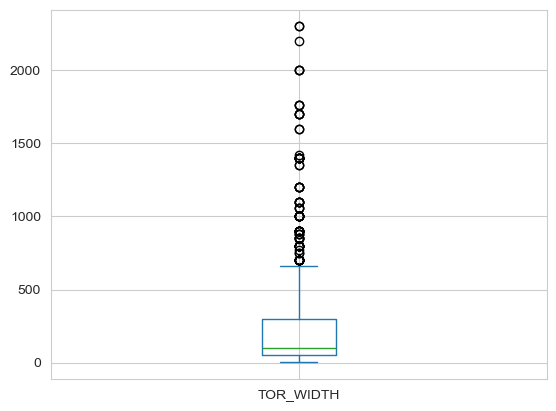

In [434]:
d1['TOR_WIDTH'].plot.box()

In [435]:
d1.sort_values('TOR_WIDTH', ascending=False).head(10)

,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,DAMAGE_PROPERTY_NUM,DAMAGE_CROPS_NUM,STATE_ABBR,TOR_LENGTH,TOR_WIDTH,END_LOCATION,BEGIN_DATETIME,END_DATETIME,DURATION
586,DELAWARE CO.,ROW,05/25/2024,1,0,0,150000,0,OK,1.80,2300,ROW,2024-05-25 23:59:00,2024-05-26 00:01:00,120.0
417,POTTAWATOMIE CO.,TECUMSEH,04/19/2023,2,0,0,4000000,0,OK,14.50,2300,AYDELOTTE,2023-04-19 20:39:00,2023-04-19 21:14:00,2100.0
409,CLEVELAND CO.,LAKE THUNDERBIRD DAM,04/19/2023,2,0,0,750000,0,OK,3.50,2200,LAKE THUNDERBIRD DAM,2023-04-19 19:47:00,2023-04-19 19:57:00,600.0
583,MAYES CO.,SALINA,05/25/2024,1,0,0,1000000,0,OK,6.10,2000,SALINA,2024-05-25 23:07:00,2024-05-25 23:19:00,720.0
581,ROGERS CO.,COLLINSVILLE,05/25/2024,3,0,19,40000000,0,OK,18.70,2000,SEQUOYAH,2024-05-25 22:19:00,2024-05-25 22:48:00,1740.0
575,JACKSON CO.,DUKE,05/23/2024,2,0,0,300000,0,OK,15.10,2000,DUKE,2024-05-23 18:04:00,2024-05-23 18:57:00,3180.0
506,HUGHES CO.,SPAULDING,04/27/2024,3,2,4,1500000,0,OK,20.50,1760,WETUMKA,2024-04-27 21:36:00,2024-04-27 22:04:00,1680.0
333,SEMINOLE CO.,SEMINOLE,05/04/2022,2,0,0,300000,0,OK,12.50,1760,LITTLE,2022-05-04 17:44:00,2022-05-04 18:14:00,1800.0
557,CUSTER CO.,BUTLER,05/19/2024,2,0,0,250000,0,OK,6.70,1760,CUSTER CITY,2024-05-19 18:28:00,2024-05-19 18:44:00,960.0
1022,MIDLAND CO.,WARFIELD,05/30/2024,2,0,0,75000,0,TX,10.27,1700,WARFIELD,2024-05-30 16:10:00,2024-05-30 16:41:00,1860.0


The width of these tornados in feet is not unordinary, I will not be getting rid of the outliers.

### DURATION

<Axes: >

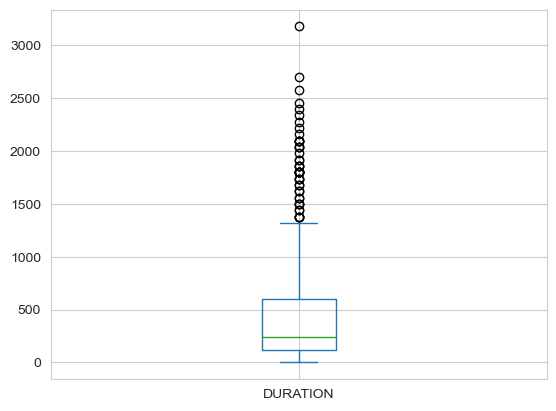

In [438]:
d1['DURATION'].plot.box()

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_79820/827238602.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='TOR_F_SCALE', y='DURATION', data=d1, palette='winter')


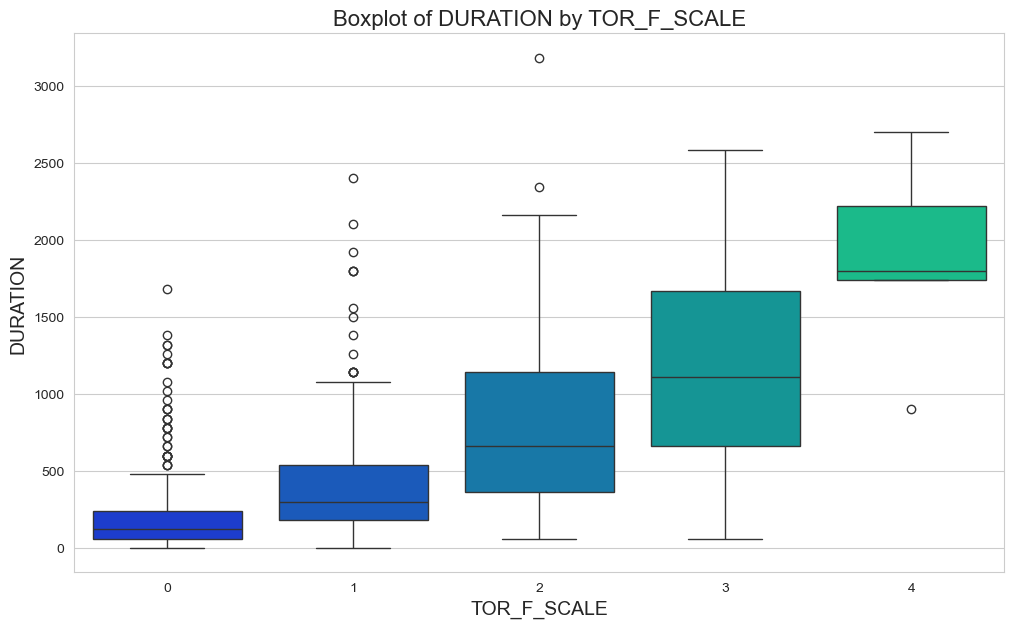

In [439]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='TOR_F_SCALE', y='DURATION', data=d1, palette='winter')

# Adding title and labels
plt.title("Boxplot of DURATION by TOR_F_SCALE", fontsize=16)
plt.xlabel("TOR_F_SCALE", fontsize=14)
plt.ylabel("DURATION", fontsize=14)

# Display the plot
plt.show()

I will be removing tornados that are outliers per each EF scale because the EF-scale is based on how violent and damaging a tornado is, if the tornado lasts longer it is more likely more violent. It is best to match it based on the EF-scale. 

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_79820/827238602.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='TOR_F_SCALE', y='DURATION', data=d1, palette='winter')


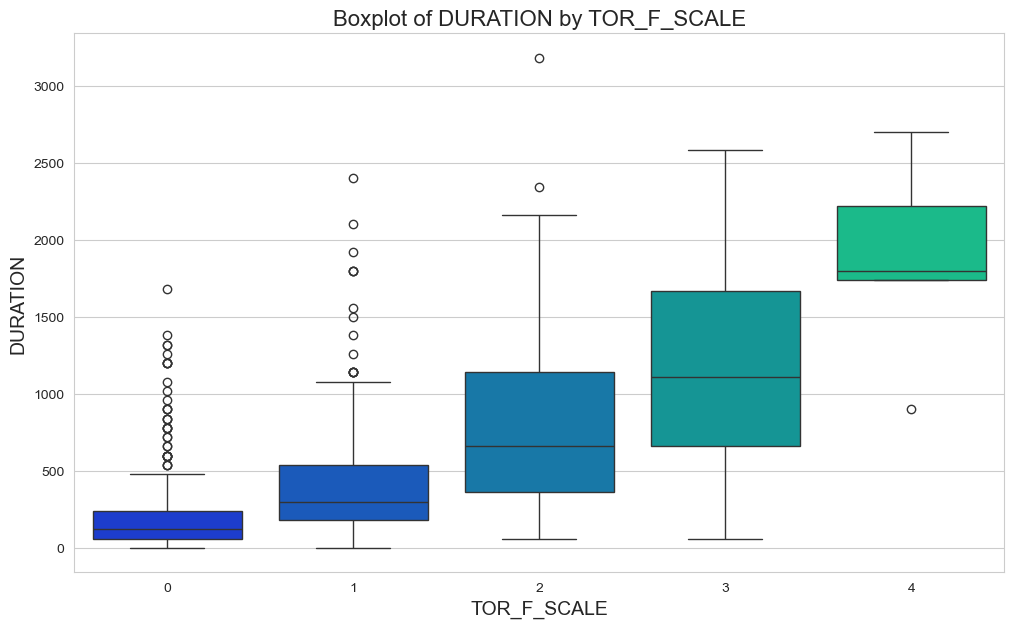

In [441]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='TOR_F_SCALE', y='DURATION', data=d1, palette='winter')

# Adding title and labels
plt.title("Boxplot of DURATION by TOR_F_SCALE", fontsize=16)
plt.xlabel("TOR_F_SCALE", fontsize=14)
plt.ylabel("DURATION", fontsize=14)

# Display the plot
plt.show()

### Outlier relationship to with response variable

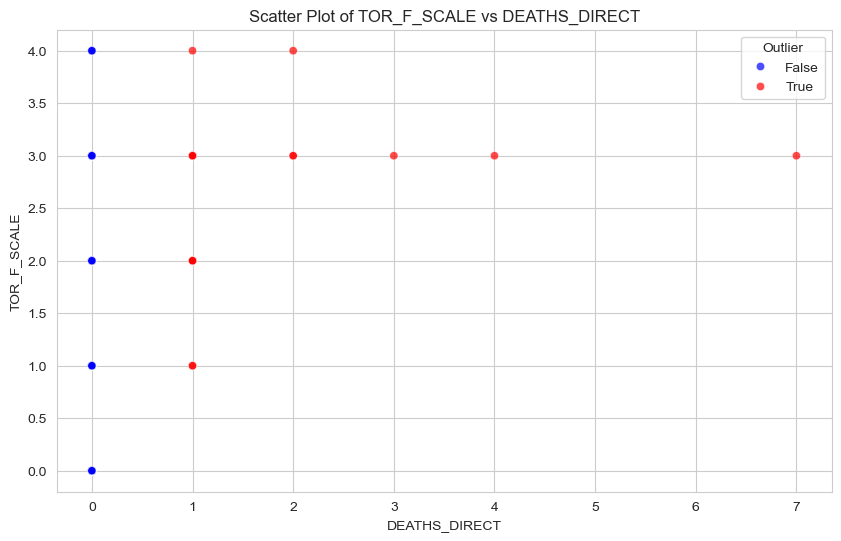

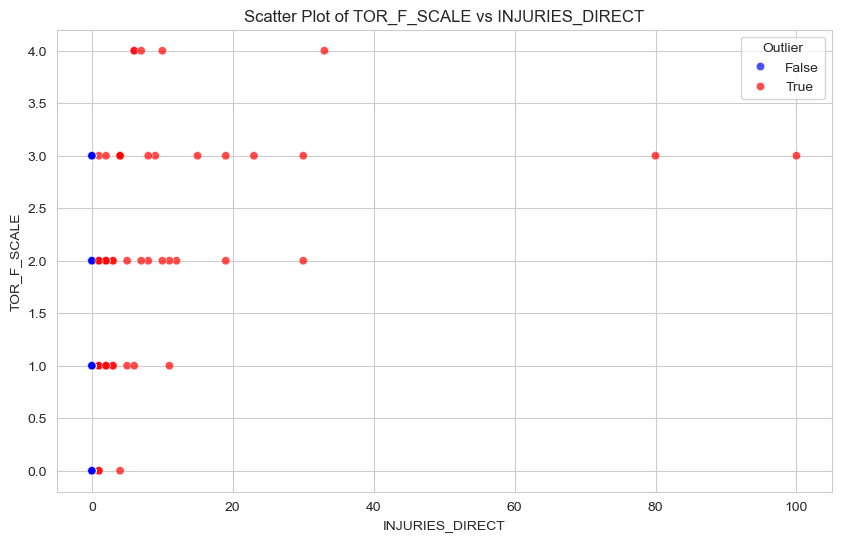

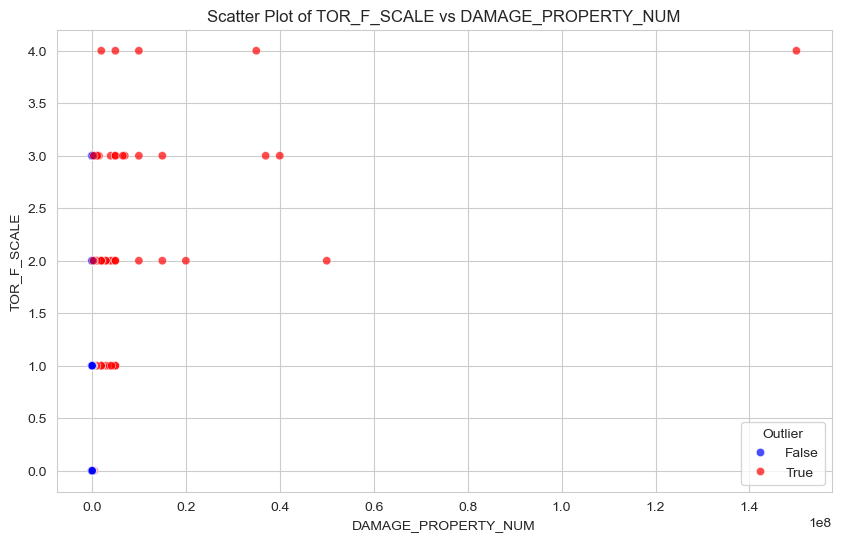

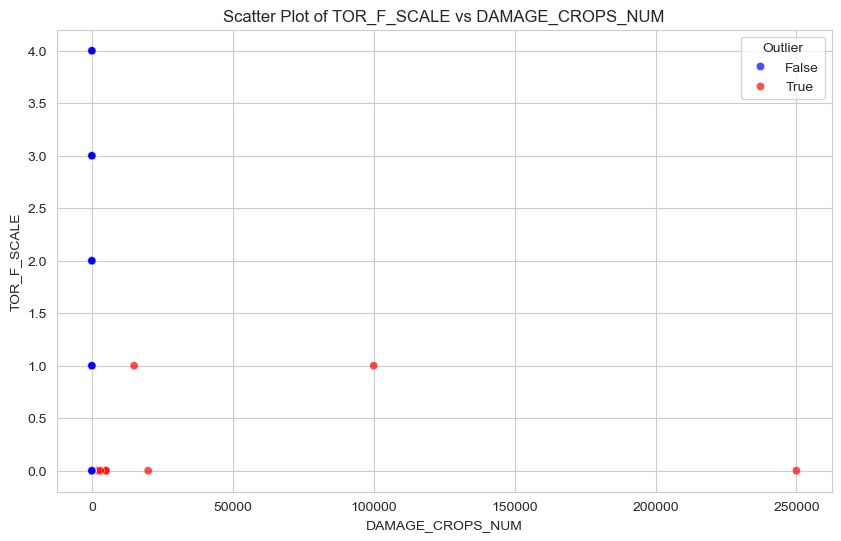

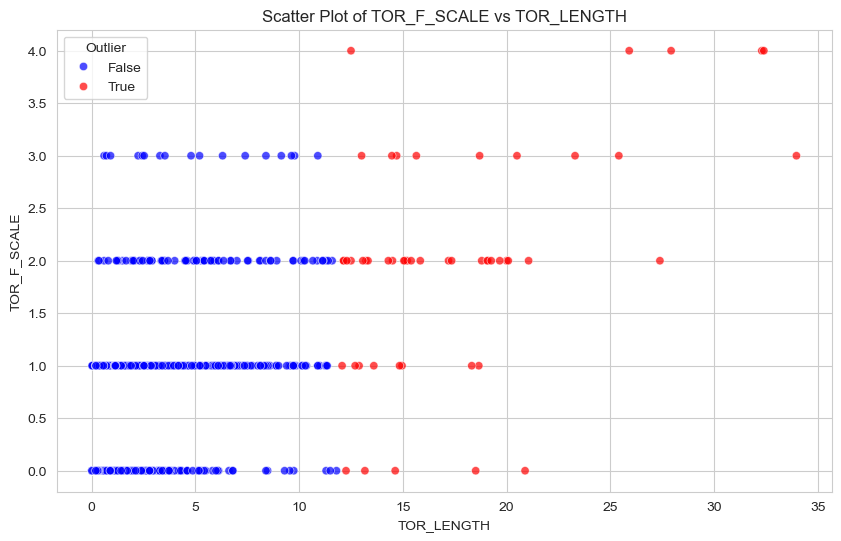

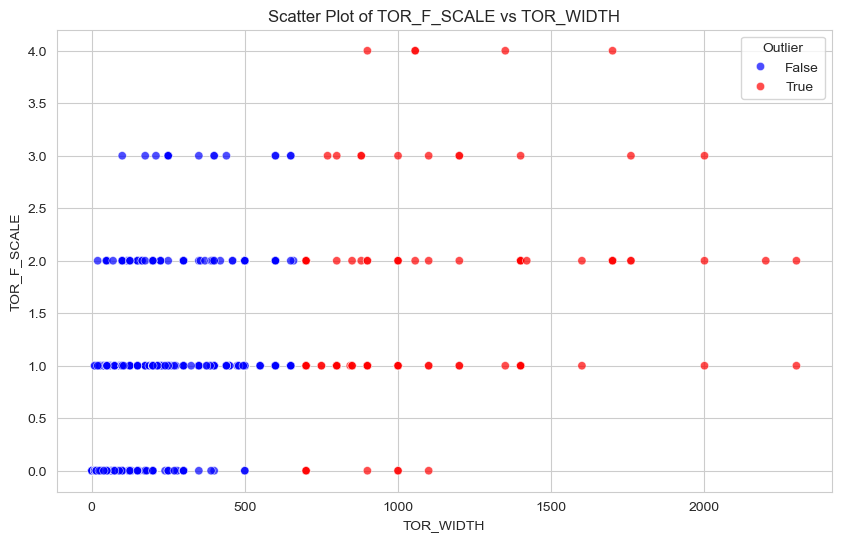

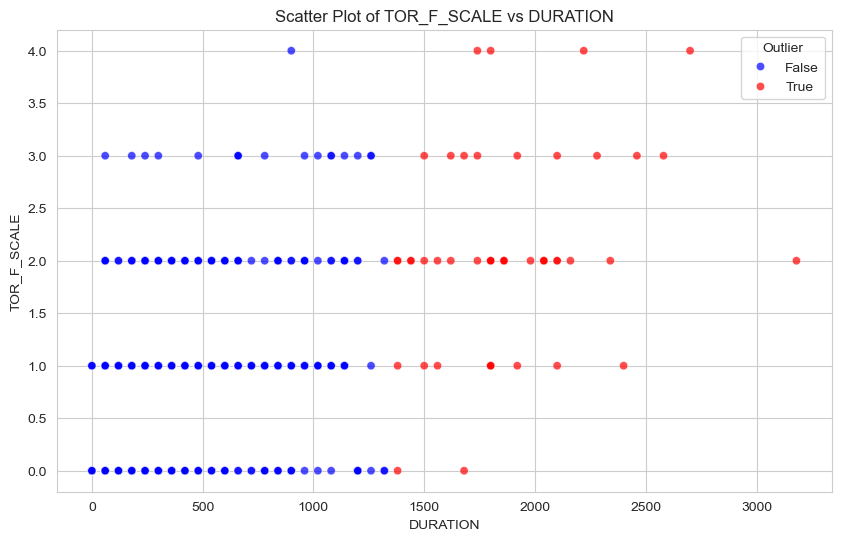

In [443]:
response_variable = 'TOR_F_SCALE'
predictor_variables =    ['DEATHS_DIRECT', 'INJURIES_DIRECT', 'DAMAGE_PROPERTY_NUM', 
    'DAMAGE_CROPS_NUM', 'TOR_LENGTH','TOR_WIDTH', 'DURATION']

# Identify outliers for each predictor using the IQR method
for predictor in predictor_variables:
    Q1 = d1[predictor].quantile(0.25)
    Q3 = d1[predictor].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Create an outlier column for the current predictor
    d1['is_outlier'] = ~d1[predictor].between(lower_bound, upper_bound)

    # Create scatter plot
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=d1, 
        x=predictor, 
        y=response_variable, 
        hue='is_outlier', 
        palette={False: 'blue', True: 'red'},
        alpha=0.7
    )

    # Add plot labels and legend
    plt.title(f"Scatter Plot of {response_variable} vs {predictor}")
    plt.xlabel(predictor)
    plt.ylabel(response_variable)
    plt.legend(title="Outlier")
    plt.show()

    # Drop the temporary 'is_outlier' column
    d1.drop(columns=['is_outlier'], inplace=True)

### Scaling and Transforming Data

In [445]:
d1.dtypes

CZ_NAME_STR                    object
BEGIN_LOCATION                 object
BEGIN_DATE                     object
TOR_F_SCALE                     int64
DEATHS_DIRECT                   int64
INJURIES_DIRECT                 int64
DAMAGE_PROPERTY_NUM             int64
DAMAGE_CROPS_NUM                int64
STATE_ABBR                     object
TOR_LENGTH                    float64
TOR_WIDTH                       int64
END_LOCATION                   object
BEGIN_DATETIME         datetime64[ns]
END_DATETIME           datetime64[ns]
DURATION                      float64
dtype: object

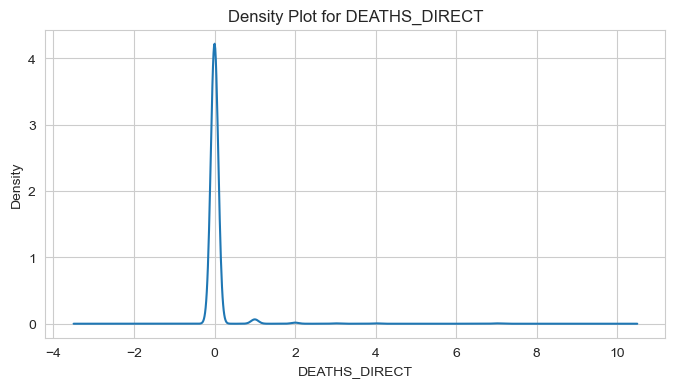

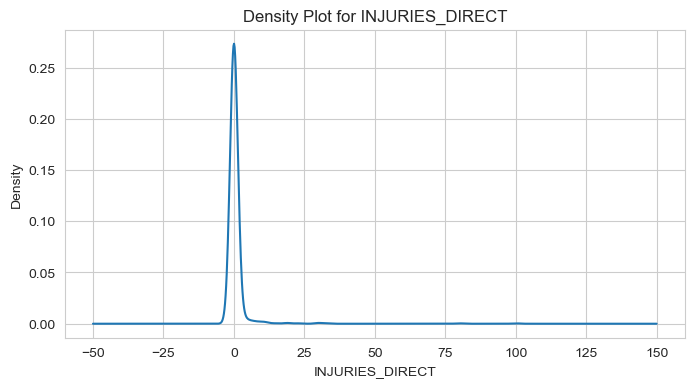

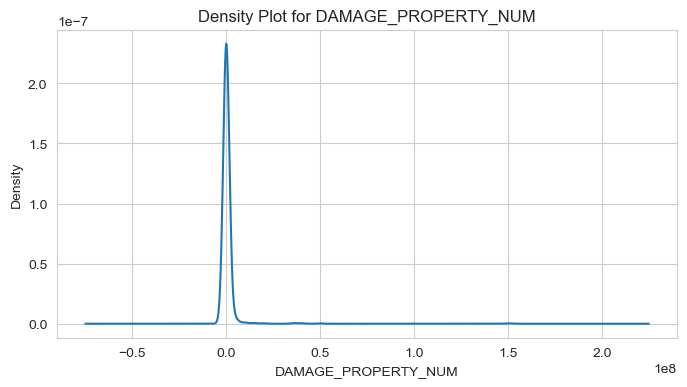

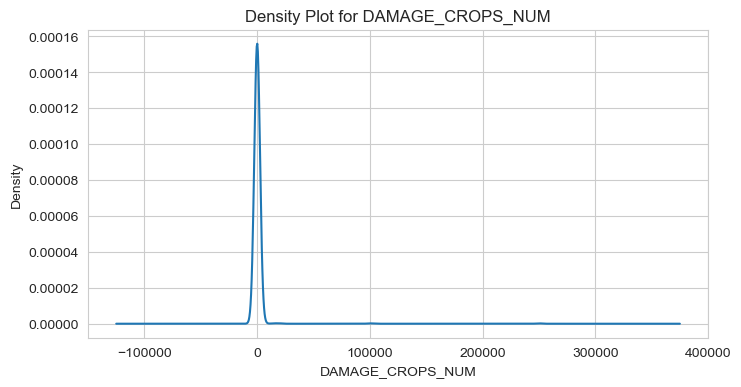

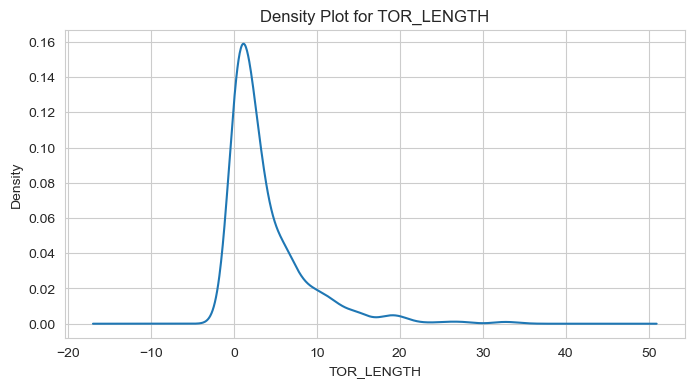

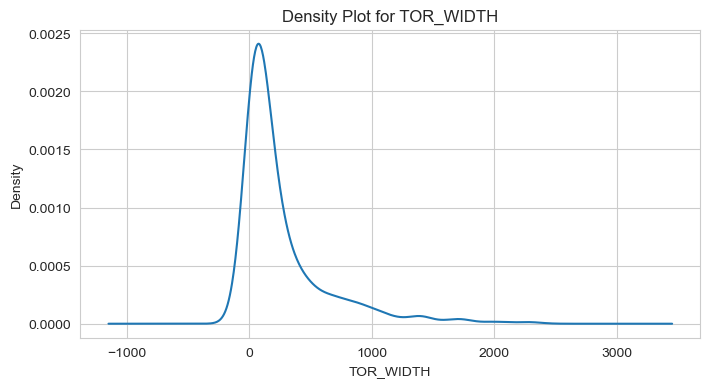

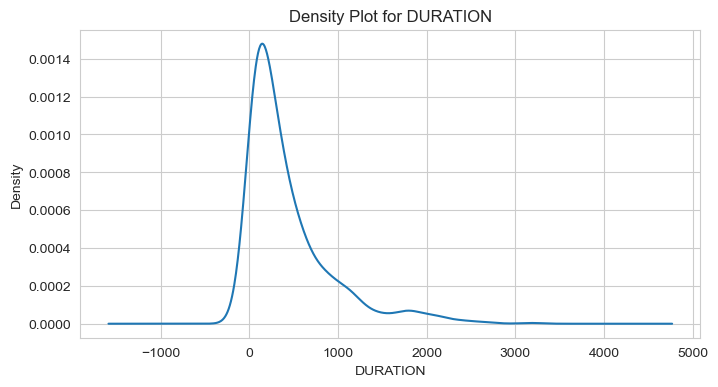

In [446]:
# Columns that require transformation to reduce skew
columns_to_transform = [
   'DEATHS_DIRECT', 'INJURIES_DIRECT', 'DAMAGE_PROPERTY_NUM', 
    'DAMAGE_CROPS_NUM', 'TOR_LENGTH','TOR_WIDTH','DURATION'
]

# Apply log transformation
for col in columns_to_transform:
    d1[f'{col}_log'] = np.log1p(d1[col])
    
for col in columns_to_transform:
    plt.figure(figsize=(8, 4))
    d1[col].plot.density()
    plt.title(f'Density Plot for {col}')
    plt.xlabel(col)
    plt.show()

Looking at these density plots, the data is skewed for all the numerical columns. This means I will need to transform and scale the data. I'm going to use a log transformation because this data has a very wide range and a lot of outliers to handle that are important to keep. Because there are also such grave differences  in the count. The majority of the variables sit at zero but that can skew the impact of larger variables to predict larger EF-scale tornados which is why it is a good idea to scale. 

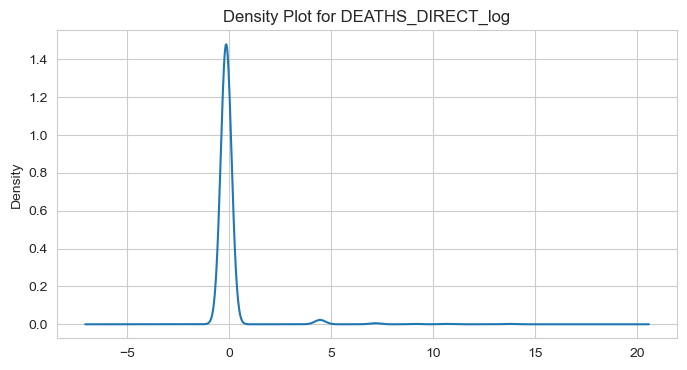

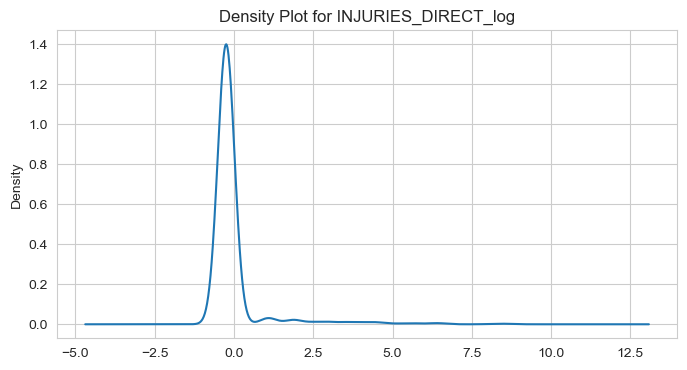

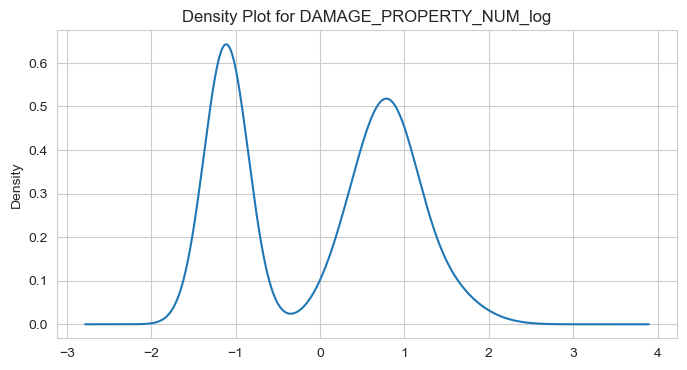

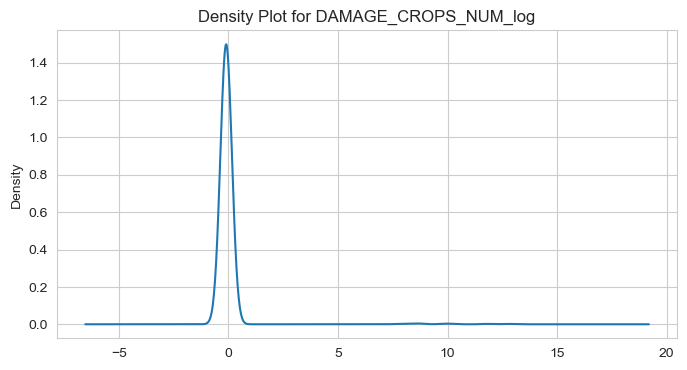

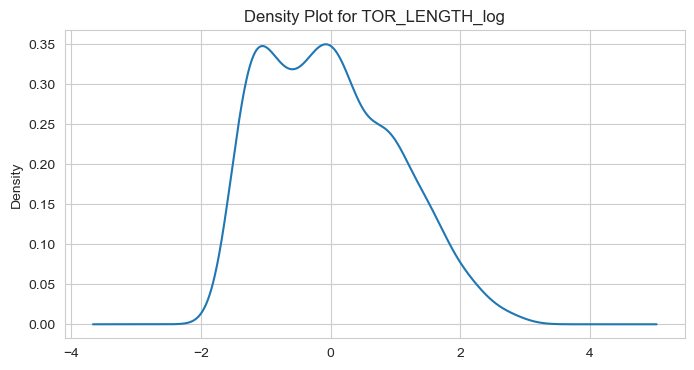

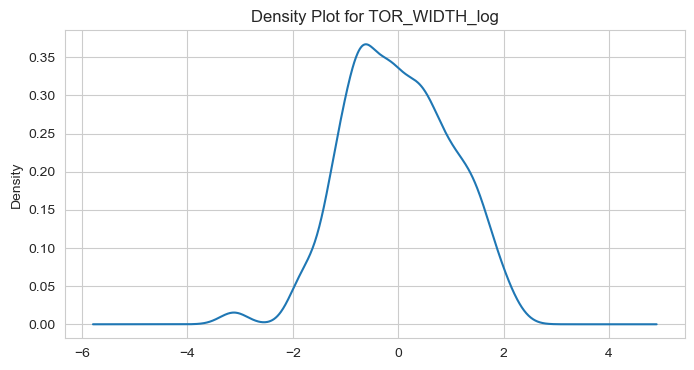

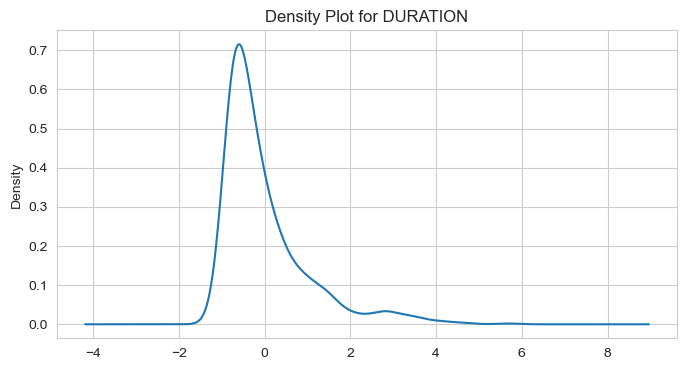

In [448]:
columns_to_scale = [
 'DEATHS_DIRECT_log', 'INJURIES_DIRECT_log', 'DAMAGE_PROPERTY_NUM_log', 
    'DAMAGE_CROPS_NUM_log', 'TOR_LENGTH_log','TOR_WIDTH_log', 'DURATION'
]
scaler = StandardScaler()
d1[columns_to_scale] = scaler.fit_transform(d1[columns_to_scale])

for col in columns_to_scale:
    plt.figure(figsize=(8, 4))
    d1[col].plot.density()
    plt.title(f'Density Plot for {col}')
    plt.show()

looking at the direct deaths,injuries direct,crop damage, and duration it still looks a little skewed. This skewness is just from the amount of commonality of a low grade tornado. Most tornados do not cause any damage or deaths and are averaged to only last less than 10 minutes. Length and width look more normal now so I don't need to worry about them. 

## Feature Selection

In [451]:
d1.dtypes

CZ_NAME_STR                        object
BEGIN_LOCATION                     object
BEGIN_DATE                         object
TOR_F_SCALE                         int64
DEATHS_DIRECT                       int64
INJURIES_DIRECT                     int64
DAMAGE_PROPERTY_NUM                 int64
DAMAGE_CROPS_NUM                    int64
STATE_ABBR                         object
TOR_LENGTH                        float64
TOR_WIDTH                           int64
END_LOCATION                       object
BEGIN_DATETIME             datetime64[ns]
END_DATETIME               datetime64[ns]
DURATION                          float64
DEATHS_DIRECT_log                 float64
INJURIES_DIRECT_log               float64
DAMAGE_PROPERTY_NUM_log           float64
DAMAGE_CROPS_NUM_log              float64
TOR_LENGTH_log                    float64
TOR_WIDTH_log                     float64
DURATION_log                      float64
dtype: object

#### Predictive Features
I will use the following categorical columns:
* STATE_ABBR
* BEGIN_DATETIME

I will use the following numerical columns:
* DEATHS_DIRECT_log
* INJURIES_DIRECT_log
* DAMAGE_PROPERTY_NUM_log
* DAMAGE_CROPS_NUM_log
* TOR_LENGTH_log
* TOR_WIDTH_log
* DURATION_log

#### Response Feature
The response variable is TOR_F_SCALE that we are trying to predict.

The inclusion of state and date allows for a better understanding of how location and seasonality impact the strength of a tornado. By using transformed and scaled numerical columns, the data provides a more accurate representation of tornado characteristics and damage produced, which can enhance predictive modeling for meteorologists. It will help minimize skewness and outlier impact by using the transformed and scaled columns. 

## Relationships between selected variables

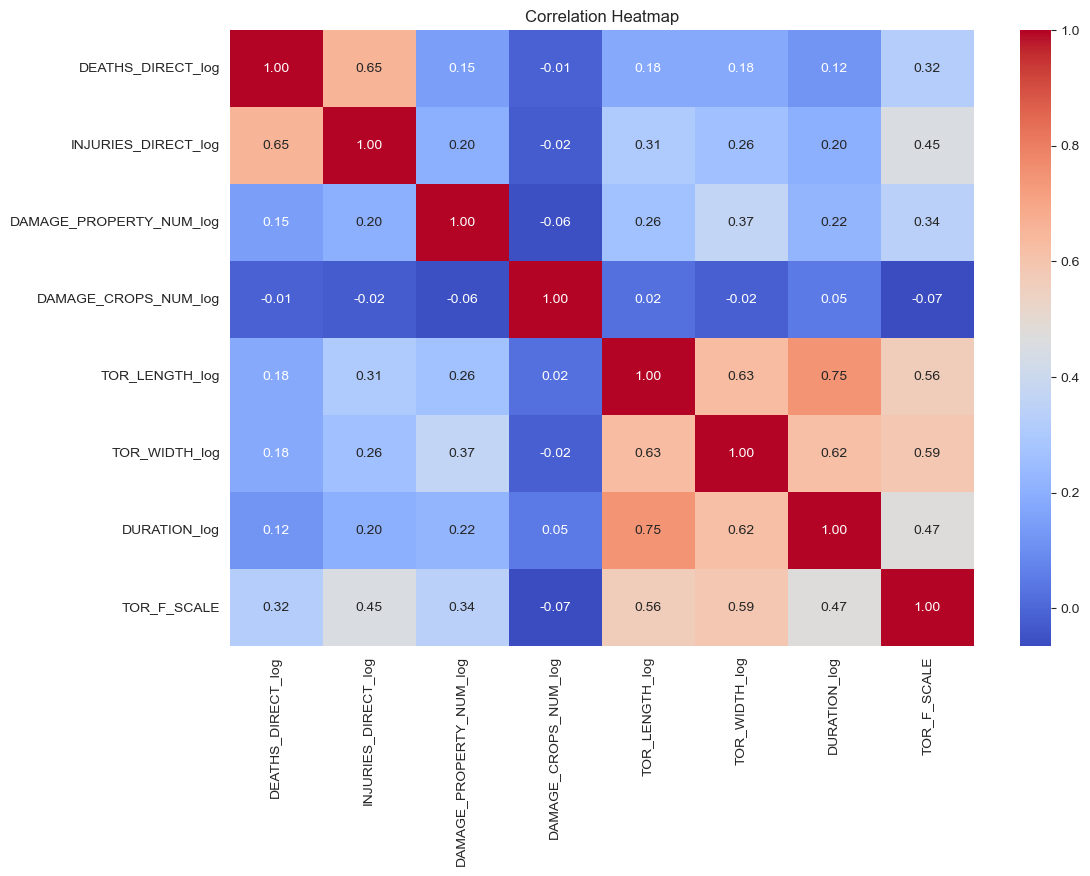

In [455]:
columns_to_include = ['DEATHS_DIRECT_log', 'INJURIES_DIRECT_log', 'DAMAGE_PROPERTY_NUM_log', 
                      'DAMAGE_CROPS_NUM_log', 'TOR_LENGTH_log', 'TOR_WIDTH_log', 'DURATION_log', 'TOR_F_SCALE']

# Filter the dataset to include only the specified columns
d1_selected = d1[columns_to_include]

# Plot the correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(d1_selected.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlation Heatmap')
plt.show()

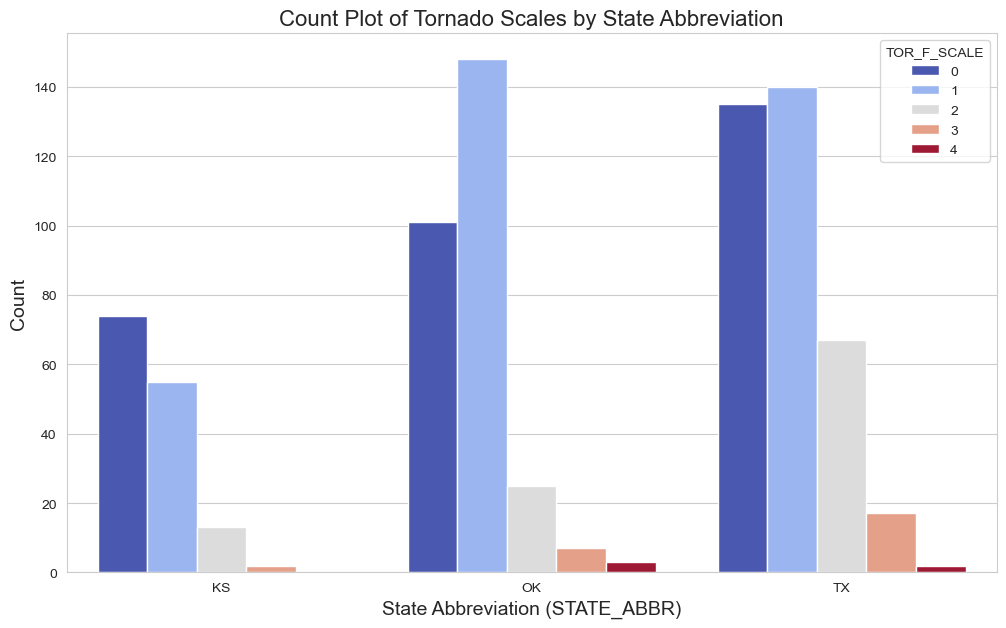

In [456]:
sns.set_style('whitegrid')
plt.figure(figsize=(12, 7))
sns.countplot(x='STATE_ABBR', hue='TOR_F_SCALE', data=d1, palette='coolwarm')

# Adding title and labels
plt.title("Count Plot of Tornado Scales by State Abbreviation", fontsize=16)
plt.xlabel("State Abbreviation (STATE_ABBR)", fontsize=14)
plt.ylabel("Count", fontsize=14)

# Display the plot
plt.show()

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_79820/3691473662.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='STATE_ABBR', data=d1, palette='viridis')


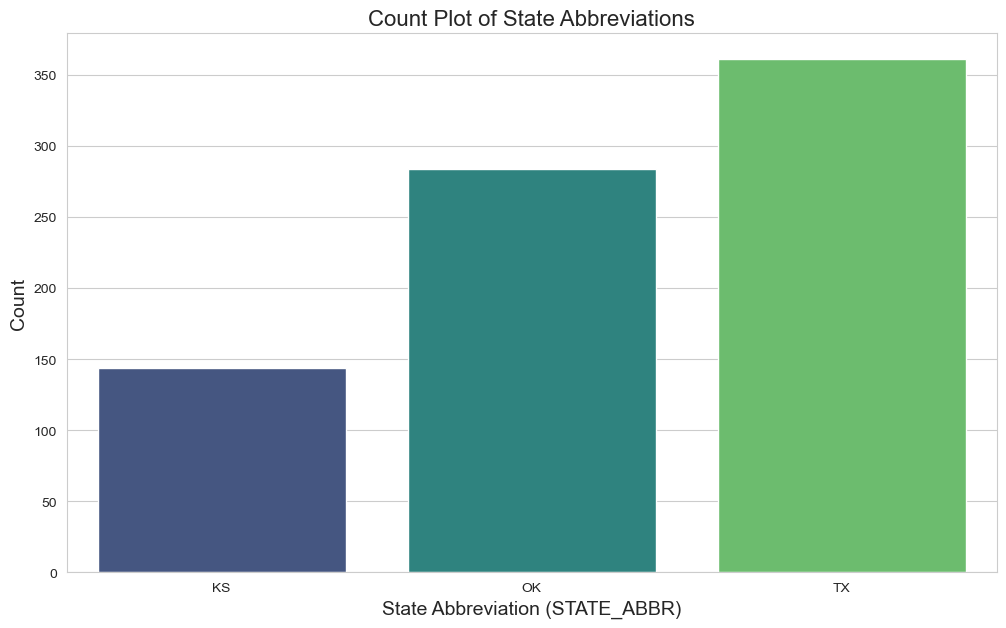

In [457]:
plt.figure(figsize=(12, 7))
sns.countplot(x='STATE_ABBR', data=d1, palette='viridis')

# Adding title and labels
plt.title("Count Plot of State Abbreviations", fontsize=16)
plt.xlabel("State Abbreviation (STATE_ABBR)", fontsize=14)
plt.ylabel("Count", fontsize=14)

# Display the plot
plt.show()

Majority of tornados are in Texas which makes sense by how big Texas is compared to Oklahoma and Kansas.

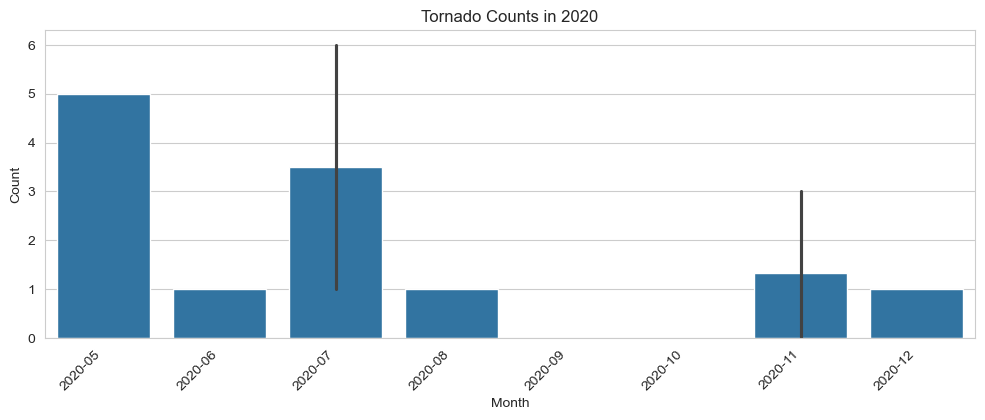

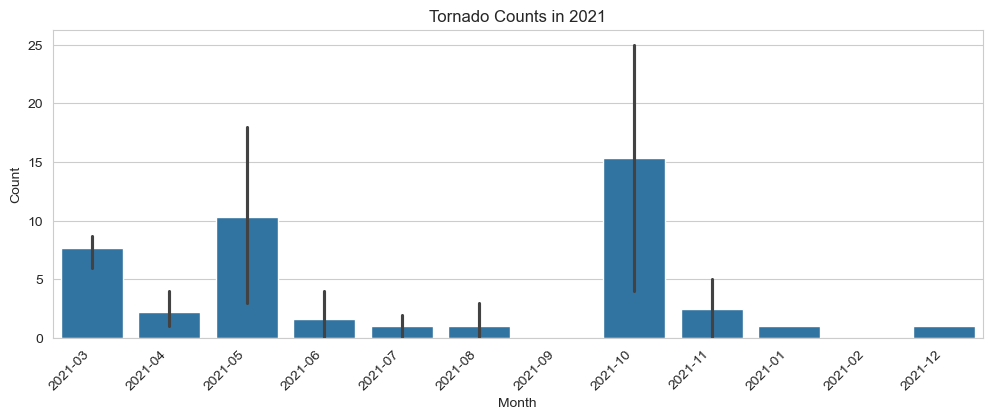

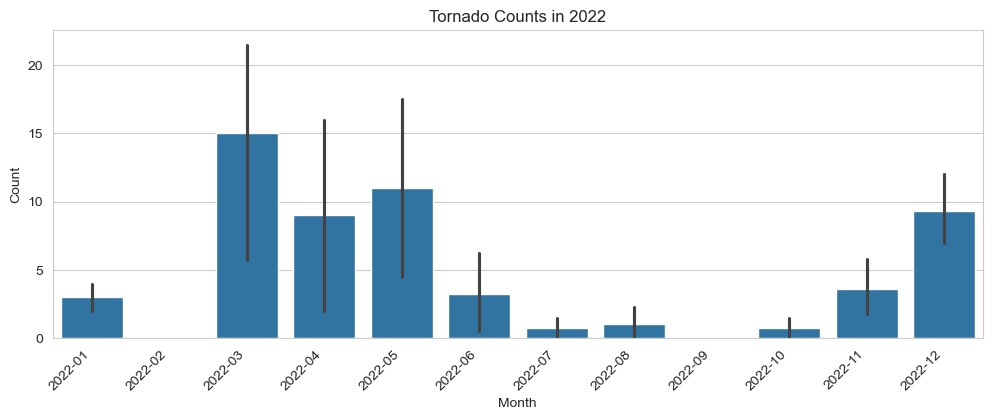

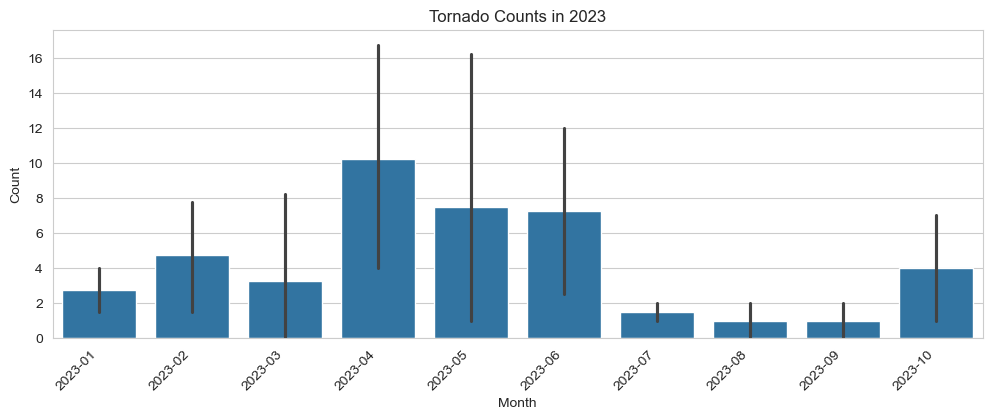

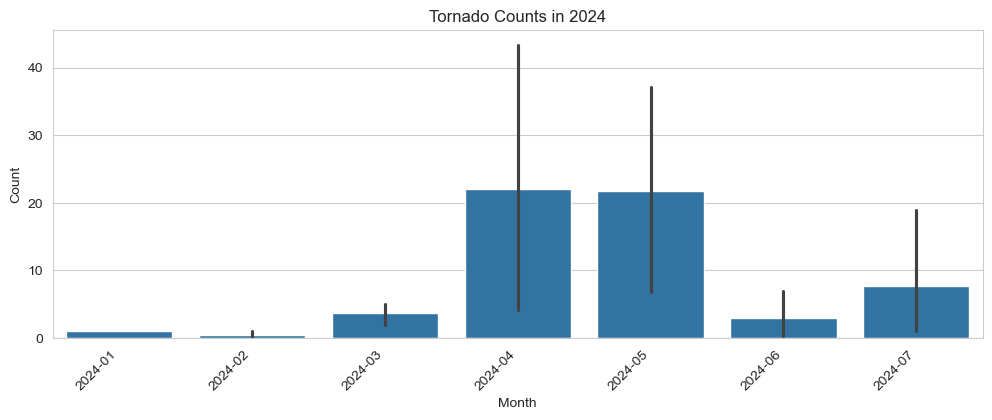

In [459]:
d1['BEGIN_DATETIME'] = pd.to_datetime(d1['BEGIN_DATETIME'], errors='coerce')
d1 = d1.dropna(subset=['BEGIN_DATETIME'])

years = [2020, 2021, 2022, 2023, 2024]  

for year in years:
    df_year = d1[d1['BEGIN_DATETIME'].dt.year == year]
        
    df_year = ( df_year.set_index('BEGIN_DATETIME').groupby('TOR_F_SCALE').resample('ME').size().reset_index(name='Count'))
    df_year['Month'] = df_year['BEGIN_DATETIME'].dt.strftime('%Y-%m')  # Format as "YYYY-MM"
    plt.figure(figsize=(12, 4))
    sns.barplot(x='Month', y='Count', data=df_year)
    plt.xticks(rotation=45, ha='right')
    plt.title(f'Tornado Counts in {year}')
    
    plt.show()

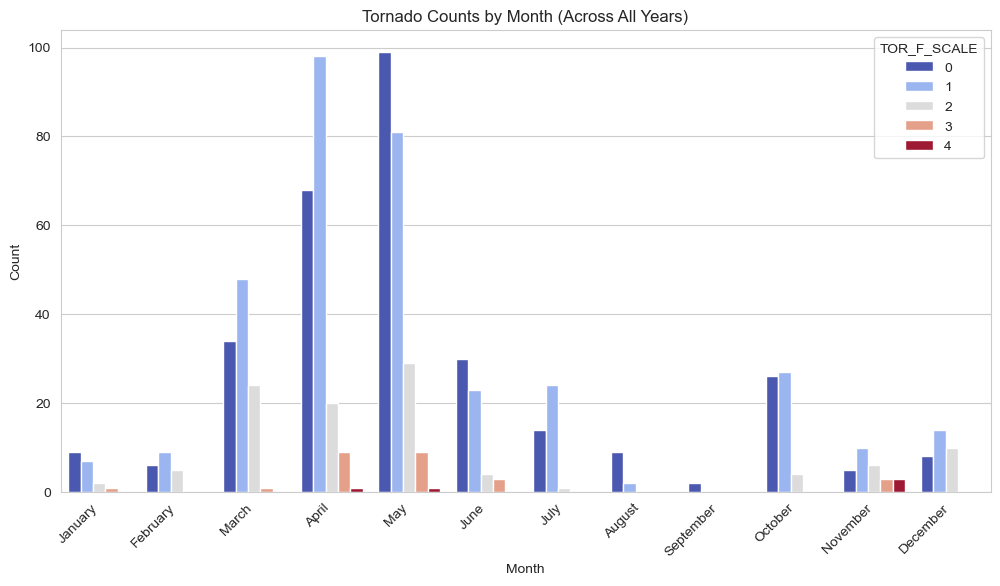

In [460]:
d1['BEGIN_DATETIME'] = pd.to_datetime(d1['BEGIN_DATETIME'], errors='coerce')
d1 = d1.dropna(subset=['BEGIN_DATETIME'])
d1['Month'] = d1['BEGIN_DATETIME'].dt.month_name()
df_monthly = d1.groupby(['Month', 'TOR_F_SCALE']).size().reset_index(name='Count')
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 
               'August', 'September', 'October', 'November', 'December']
df_monthly['Month'] = pd.Categorical(df_monthly['Month'], categories=month_order, ordered=True)

plt.figure(figsize=(12, 6))
sns.barplot(x='Month', y='Count', hue='TOR_F_SCALE', data=df_monthly, palette='coolwarm')
plt.xticks(rotation=45, ha='right')

plt.title('Tornado Counts by Month (Across All Years)')
plt.show()

It seems that the majority of tornados happen March-July and are the strongest aroudn then. Altought they are no common on November and December, they seem to be extremely strong if they do occur. 

<Figure size 2000x1200 with 0 Axes>

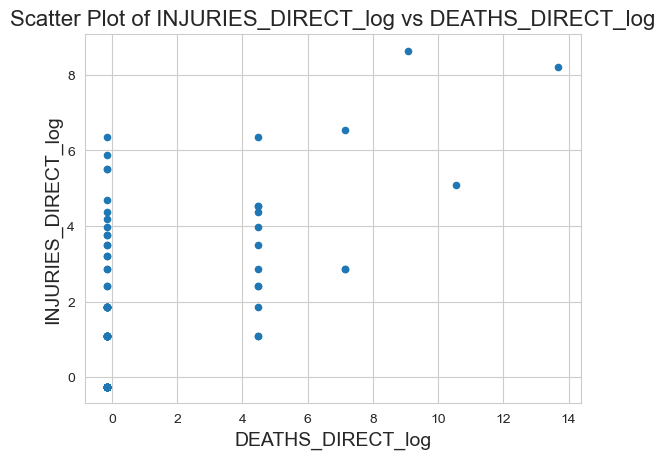

<Figure size 2000x1200 with 0 Axes>

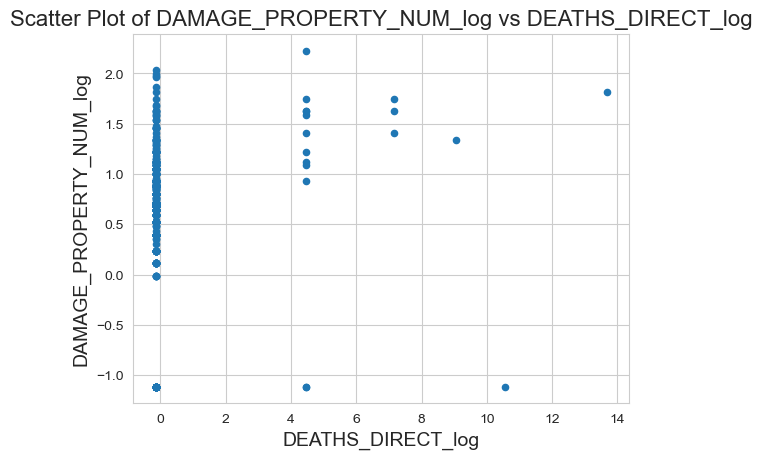

<Figure size 2000x1200 with 0 Axes>

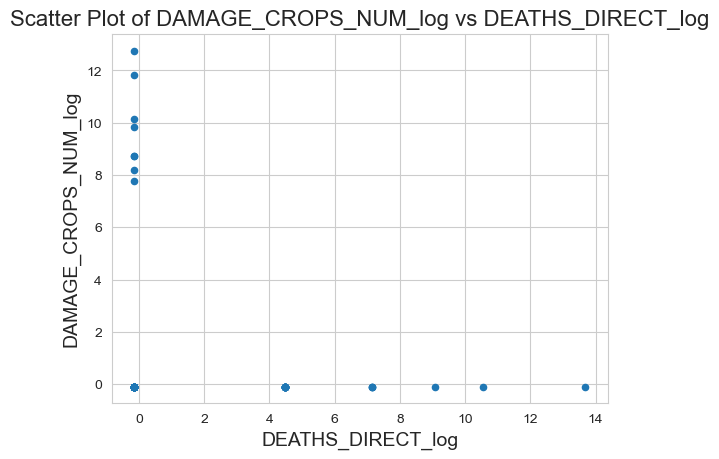

<Figure size 2000x1200 with 0 Axes>

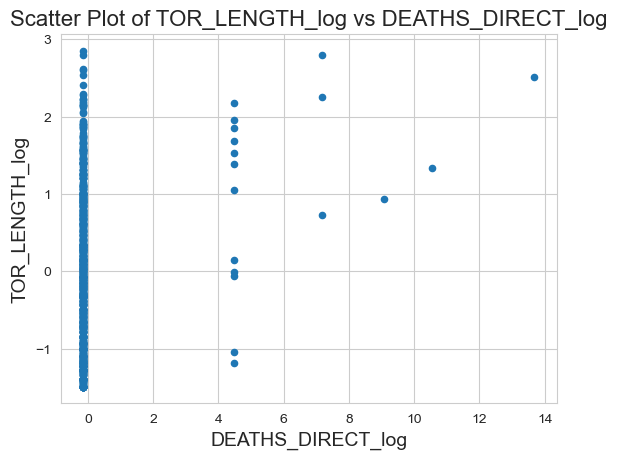

<Figure size 2000x1200 with 0 Axes>

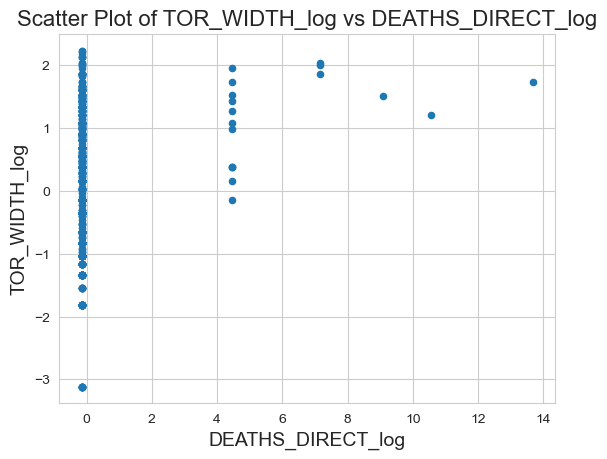

<Figure size 2000x1200 with 0 Axes>

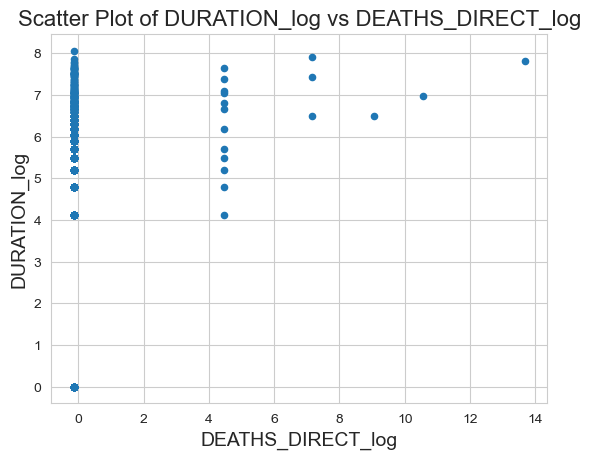

<Figure size 2000x1200 with 0 Axes>

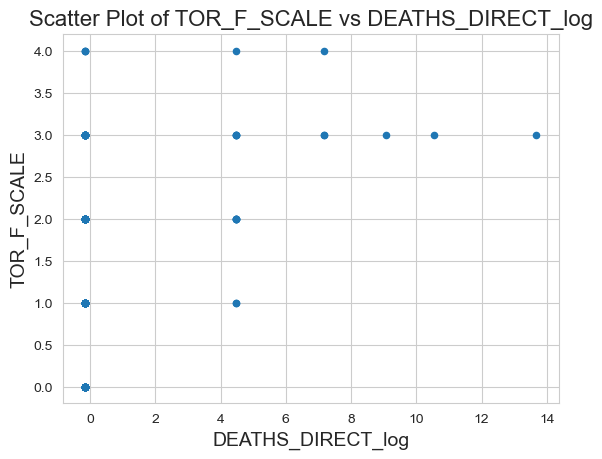

<Figure size 2000x1200 with 0 Axes>

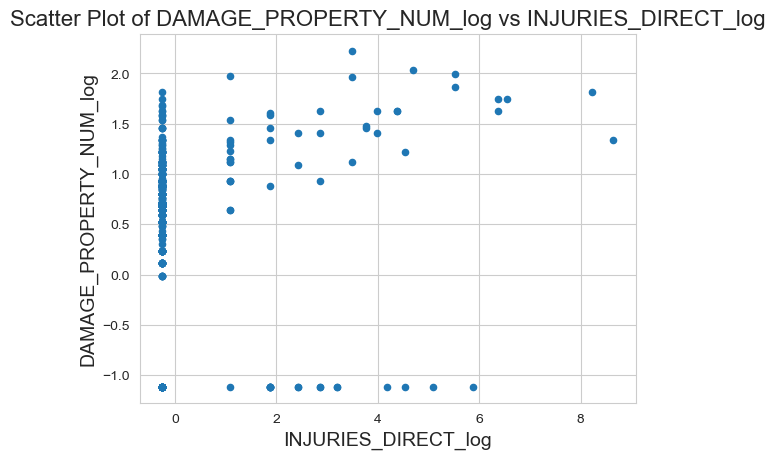

<Figure size 2000x1200 with 0 Axes>

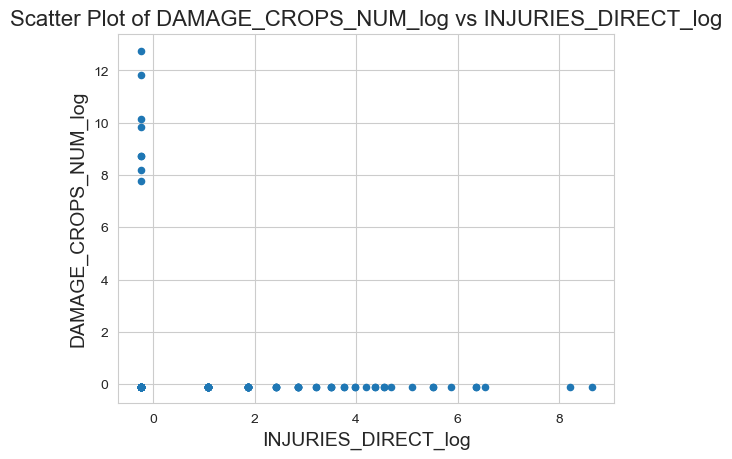

<Figure size 2000x1200 with 0 Axes>

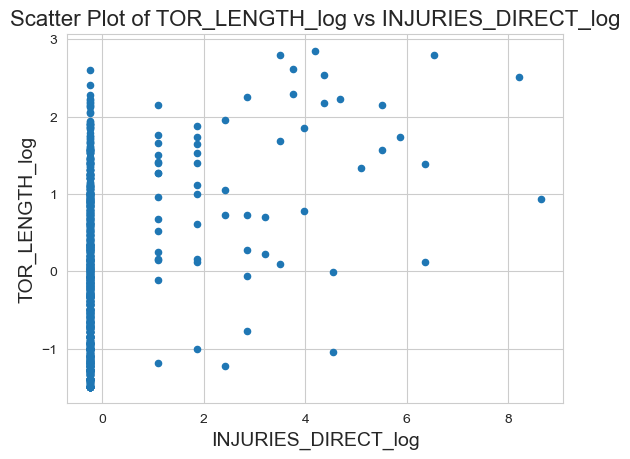

<Figure size 2000x1200 with 0 Axes>

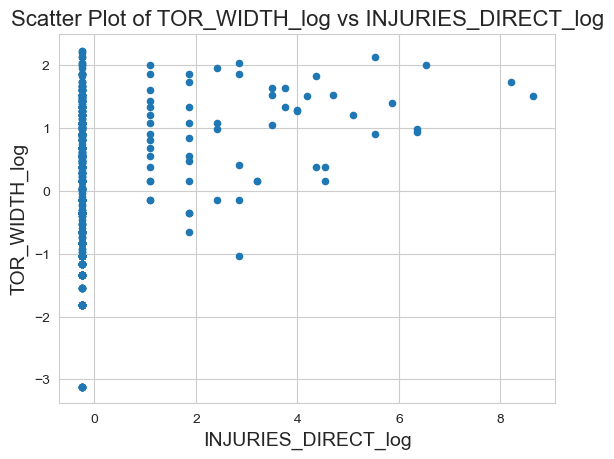

<Figure size 2000x1200 with 0 Axes>

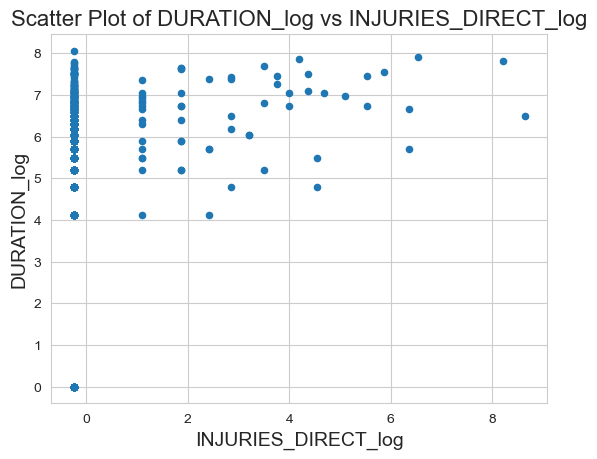

<Figure size 2000x1200 with 0 Axes>

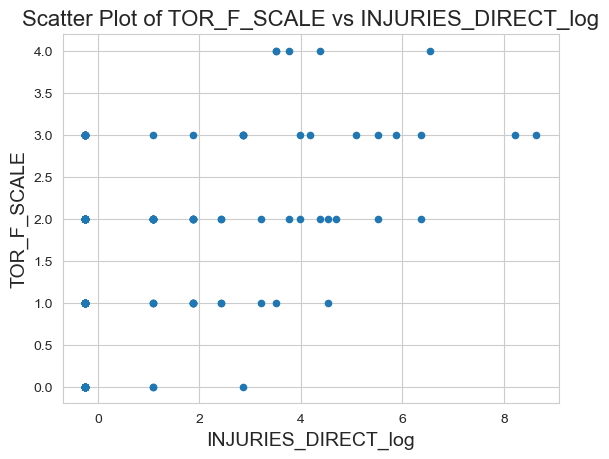

<Figure size 2000x1200 with 0 Axes>

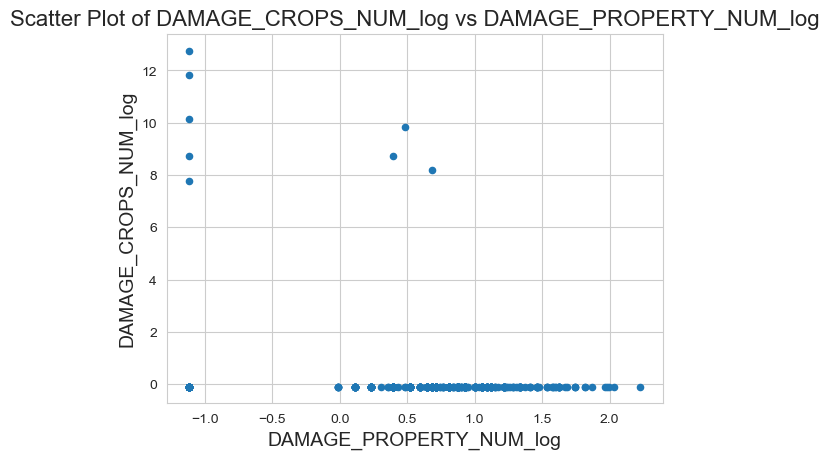

<Figure size 2000x1200 with 0 Axes>

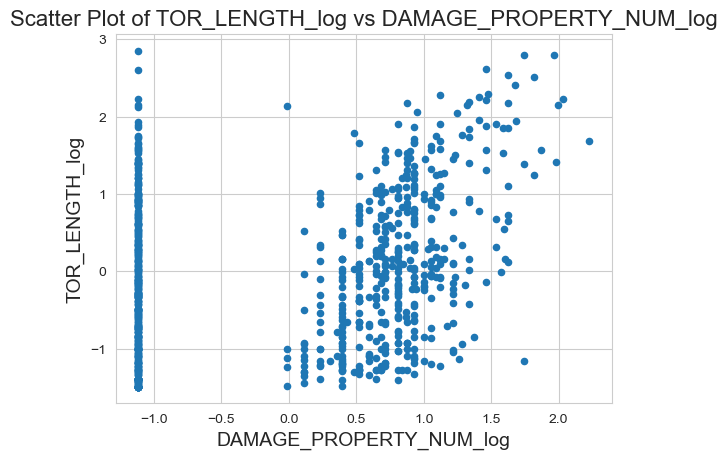

<Figure size 2000x1200 with 0 Axes>

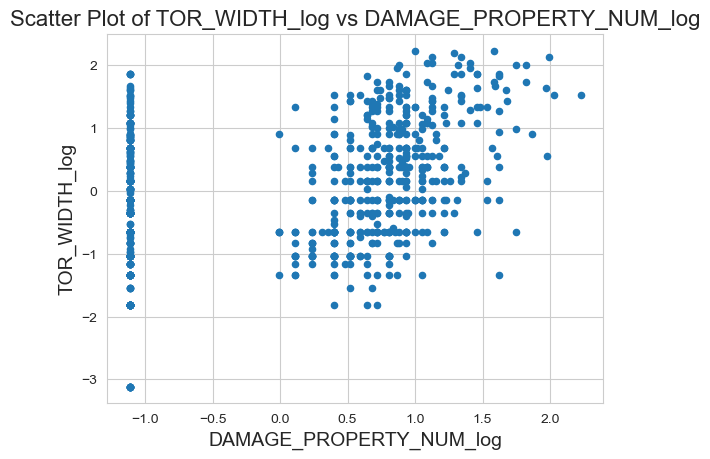

<Figure size 2000x1200 with 0 Axes>

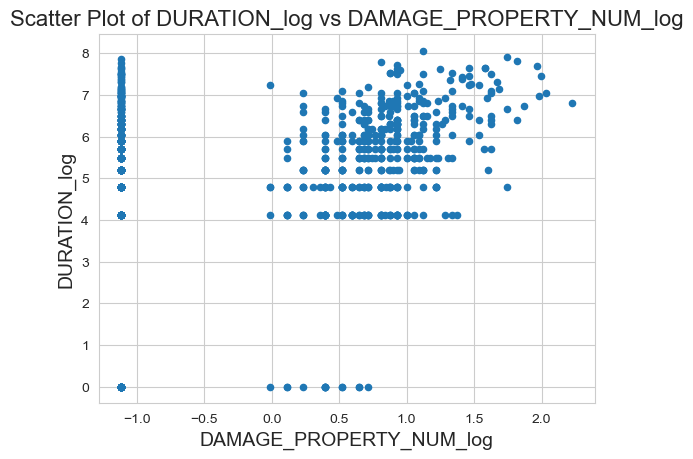

<Figure size 2000x1200 with 0 Axes>

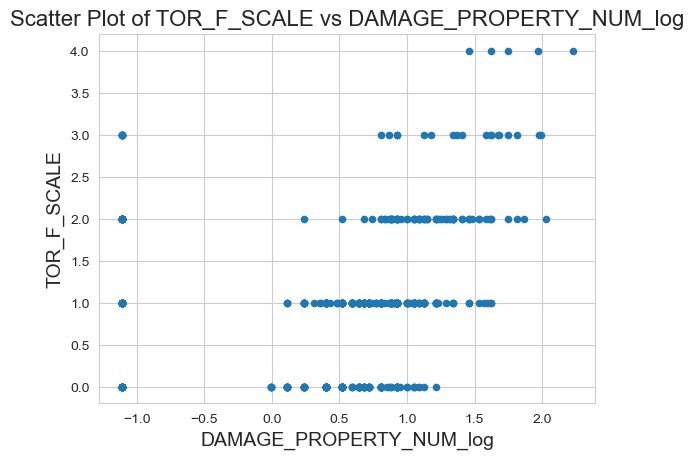

<Figure size 2000x1200 with 0 Axes>

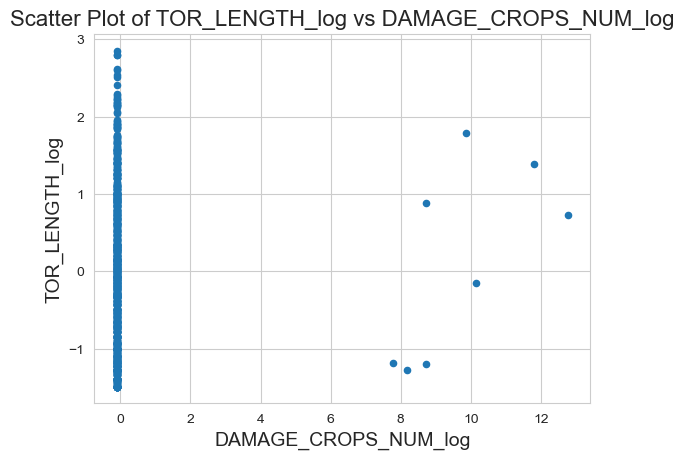

<Figure size 2000x1200 with 0 Axes>

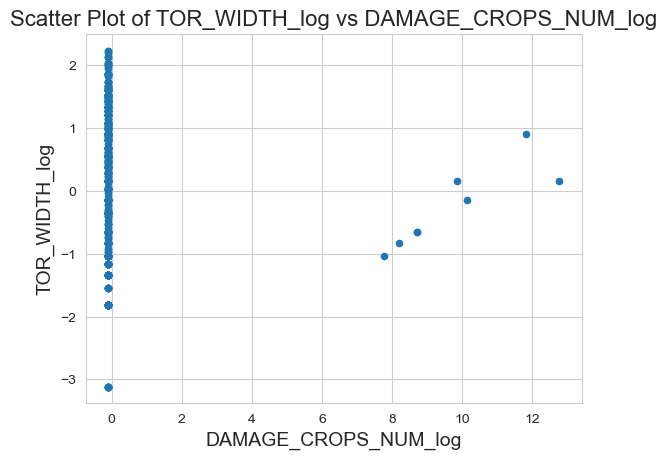

<Figure size 2000x1200 with 0 Axes>

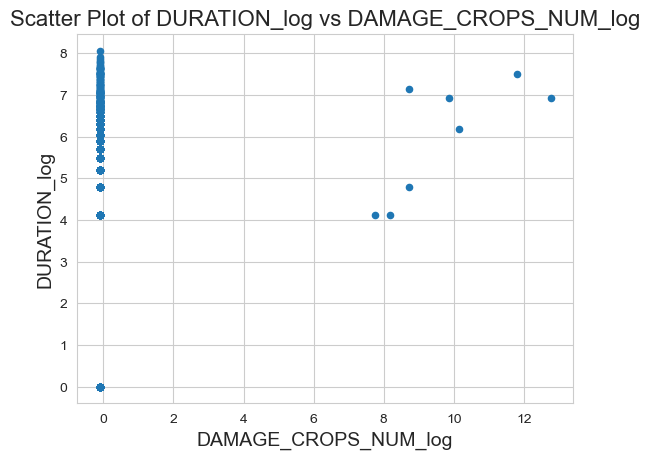

<Figure size 2000x1200 with 0 Axes>

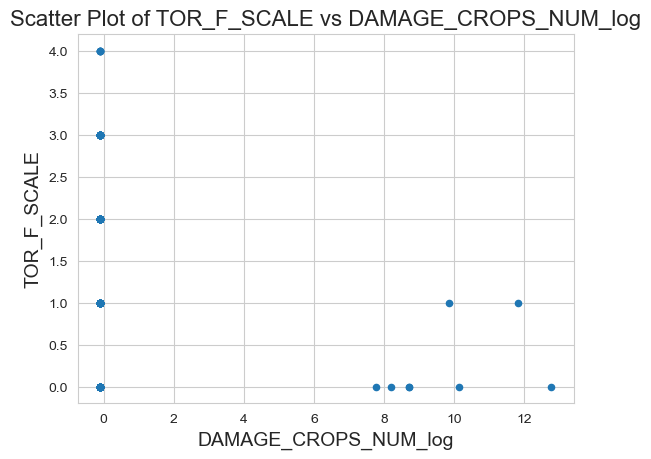

<Figure size 2000x1200 with 0 Axes>

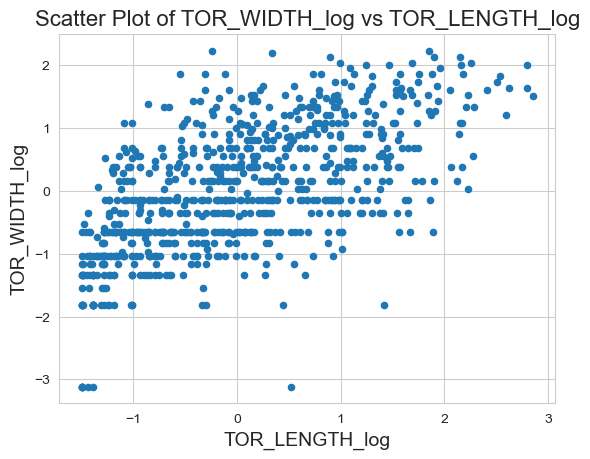

<Figure size 2000x1200 with 0 Axes>

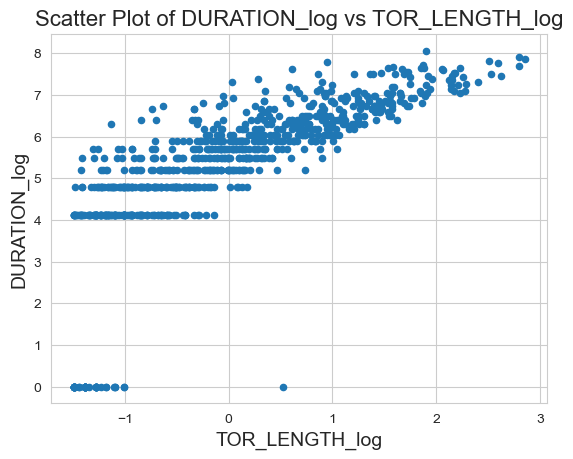

<Figure size 2000x1200 with 0 Axes>

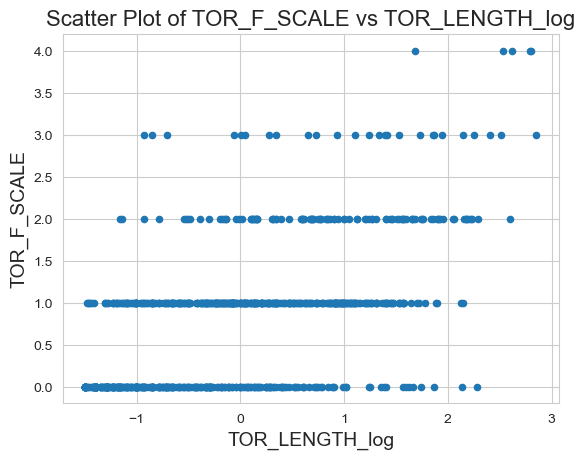

<Figure size 2000x1200 with 0 Axes>

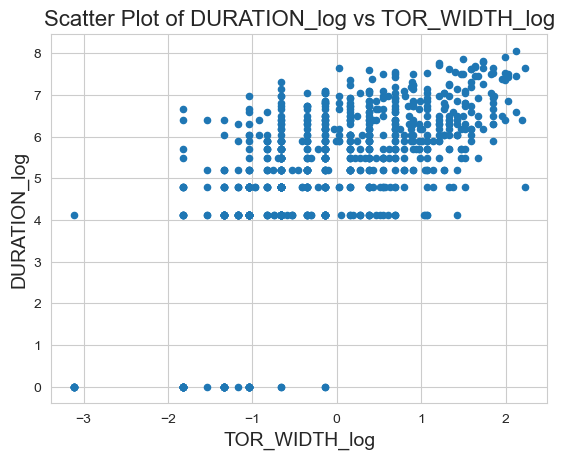

<Figure size 2000x1200 with 0 Axes>

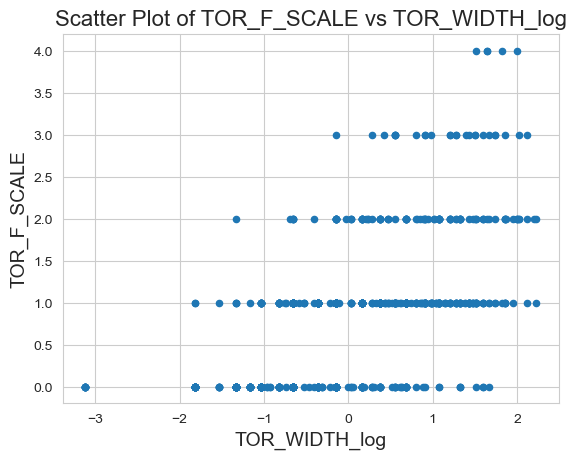

<Figure size 2000x1200 with 0 Axes>

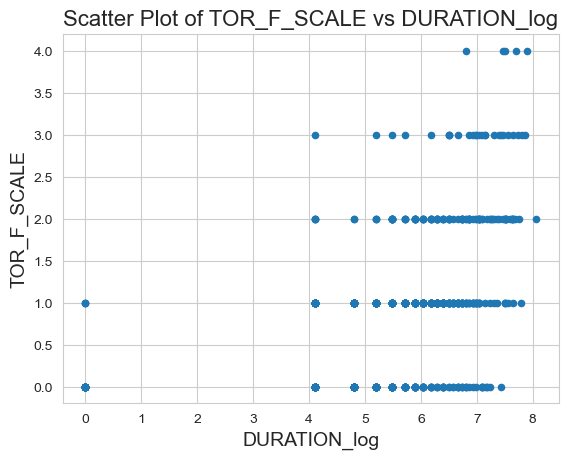

In [462]:
for item in list(combinations(d1[['DEATHS_DIRECT_log', 'INJURIES_DIRECT_log', 'DAMAGE_PROPERTY_NUM_log', 
                                  'DAMAGE_CROPS_NUM_log', 'TOR_LENGTH_log', 'TOR_WIDTH_log', 
                                  'DURATION_log', 'TOR_F_SCALE']].columns, 2)):
    plt.figure(figsize=(20, 12))
    d1.plot.scatter(x=item[0], y=item[1])
    
    # Adding title
    plt.title(f"Scatter Plot of {item[1]} vs {item[0]}", fontsize=16)
    plt.xlabel(item[0], fontsize=14)
    plt.ylabel(item[1], fontsize=14)
    
    # Display the plot
    plt.show()

### Encoding categorical variables

In [464]:
categorical_columns = ['STATE_ABBR', 'BEGIN_DATETIME']
for col in categorical_columns:
    encoder = LabelEncoder()
    d1[col] = encoder.fit_transform(d1[col])

I used LabelEncoder for my analysis because it efficiently converts categorical data like (STATE_ABBR) and (BEGIN_DATETIME) into numerical values that models can process. This method is compact, straightforward, and suitable when categories have no inherent order but need to be represented numerically for machine learning algorithms.

### Next Steps
I found that the majority of tornados occur between March and May Along with the most high-grade tornados. However, there are some in November. The highest correlation between the EF scale and tornado characteristics is the length and width of the tornado and its duration. 

### Justification for Chosen Models
In this analysis, I chose three classification models—Logistic Regression, k-Nearest Neighbors (k-NN), and Naive Bayes—for the following reasons:

* Logistic Regression: Logistic regression is widely used for classification tasks due to its simplicity and interpretability. It works well when the data has a linear relationship between the features and the target variable. Given that tornado intensity (represented by the EF scale) may be influenced by linear relationships with features like location and size, logistic regression is a natural choice.

* k-Nearest Neighbors (k-NN): k-NN is a non-parametric, instance-based learning algorithm that classifies data points based on the majority label of its neighbors. It was selected because of its simplicity and its ability to capture complex, non-linear relationships in data. However, it requires careful selection of the number of neighbors and works best with normalized or scaled data.

* Naive Bayes: Naive Bayes is based on probabilistic models and assumes independence between features. This model is particularly effective when the features are categorical or when dealing with high-dimensional data. Despite the assumption of feature independence, Naive Bayes can still perform well for many classification tasks, particularly when features are loosely correlated.

## Training Models
### Naive Bayes

In [469]:

X = d1[columns_to_scale + categorical_columns]  # Using scaled, transformed, and encoded features
y = d1['TOR_F_SCALE']  # Target variable: credit_score

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)  # Get probabilities for all classes

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

# AUC for multi-class classification using One-vs-Rest (OvR)
print("AUC:", roc_auc_score(y_test, y_pred_proba, multi_class='ovr'))

print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.4177215189873418
AUC: 0.842210480615703

Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.91      0.63        58
           1       0.00      0.00      0.00        71
           2       0.26      0.45      0.33        22
           3       0.29      0.40      0.33         5
           4       0.50      0.50      0.50         2

    accuracy                           0.42       158
   macro avg       0.30      0.45      0.36       158
weighted avg       0.23      0.42      0.29       158



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### kNN Classification

In [481]:
# Initialize the k-NN classifier (using k=5 as a starting point)
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the k-NN model
knn_model.fit(X_train, y_train)

# Predict on the test set
y_pred = knn_model.predict(X_test)
y_pred_proba = knn_model.predict_proba(X_test)  # Get probabilities for all classes

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

# AUC for multi-class classification using One-vs-Rest (OvR)
print("AUC:", roc_auc_score(y_test, y_pred_proba, multi_class='ovr'))

print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.44936708860759494
AUC: 0.6828292669486139

Classification Report:
               precision    recall  f1-score   support

           0       0.44      0.55      0.49        58
           1       0.46      0.52      0.49        71
           2       1.00      0.09      0.17        22
           3       0.00      0.00      0.00         5
           4       0.00      0.00      0.00         2

    accuracy                           0.45       158
   macro avg       0.38      0.23      0.23       158
weighted avg       0.51      0.45      0.42       158



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Logistic Regression Classification

In [483]:
# Initialize the Logistic Regression model
logreg_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the Logistic Regression model
logreg_model.fit(X_train, y_train)

# Predict on the test set
y_pred = logreg_model.predict(X_test)  # Use logreg_model for prediction
y_pred_proba = logreg_model.predict_proba(X_test)  # Get probabilities for all classes

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_pred_proba, multi_class='ovr'))  # For multi-class, use 'ovr'
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.6139240506329114
AUC: 0.8195888977082018

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.78      0.72        58
           1       0.60      0.65      0.62        71
           2       0.50      0.14      0.21        22
           3       0.50      0.40      0.44         5
           4       0.25      0.50      0.33         2

    accuracy                           0.61       158
   macro avg       0.50      0.49      0.47       158
weighted avg       0.60      0.61      0.59       158



/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Best Performing Model
Logistic Regression outperformed the other two models in terms of both accuracy (61%) and AUC (0.82). Despite its lower accuracy compared to other models, it had the highest AUC score, indicating that it had better discrimination ability, especially for distinguishing between the presence of higher EF tornadoes.
### Conclusion
#### Lessons Learned
* Model Selection: While each model had its merits, it was clear that Logistic Regression was more suitable for the data given the feature relationships. Despite its simple nature, it provided a reliable and interpretable result for the classification task.
* Data Imbalance: Many of the higher EF scale classes (particularly class 3 and 4) were poorly predicted by all models, suggesting that data imbalance or insufficient representation of these classes impacted the models' performance. Because of their rarity, it is hard to accurately predict across all models. 
#### Why the Best Performing Model is Useful
Logistic Regression is particularly useful because of its interpretability and ability to provide probabilities for each class, which is valuable for understanding how likely a tornado is to reach a certain intensity. This can guide decision-making in risk management or disaster preparedness.
#### Why Logistic Regression is the Best Performing Model
Logistic Regression performed best because of its ability to handle the data in a manner that accounts for linear relationships between features and the target class. It also handled the class imbalance better than other models, despite the presence of small classes.
#### Limitations of the Work and Future Improvements
* Data Imbalance: The skewed distribution of tornado scales led to poor model performance for certain classes (especially classes 3 and 4). To improve the model, techniques such as resampling or using class weights could be explored to handle class imbalance better.

* Feature Engineering: More advanced feature engineering, such as including interaction terms between features or using non-linear transformations, could have improved the model's performance. Additionally, feature selection to reduce noise and improve generalization might help.

* Model Tuning: I used default hyperparameters for each model. Hyperparameter tuning (e.g., for logistic regression regularization or k-NN's k-value) could improve performance. Using cross-validation for better hyperparameter estimation is also a future avenue.

* Alternative Models: Other models, such as Random Forest or Gradient Boosting, might handle class imbalance and complex relationships in the data better and could be tested in future iterations.